# BÁO CÁO VÀ TRÌNH BÀY DỰ ÁN CUỐI KỲ (ADY201m)
## Đề tài: MÔ TẢ & PHÂN LOẠI DỮ LIỆU BÁO ĐIỆN TỬ VNEXPRESS

---

### THÀNH VIÊN NHÓM VÀ PHÂN CÔNG NHIỆM VỤ:
* **Phạm Hùng Dương-HE210543:** Cào dữ liệu từ 16 chuyên mục VnExpress (`Phase 1`) & Làm sạch, kiểm tra chất lượng dữ liệu (`Phase 2`).
* **Nguyễn Hữu Hùng-HE210370:** Thiết kế bảng CSDL Microsoft SQL Server & Viết 6 câu truy vấn T-SQL phân tích nghiệp vụ (`Phase 3`).
* **Đinh Trung Hiếu-HE210142:** Vẽ 5 biểu đồ phân tích khám phá dữ liệu EDA (`Phase 4`) & Huấn luyện các mô hình học máy phân loại, hồi quy (`Phase 5 & Phase 6`).

---

## MỤC LỤC BÁO CÁO TOÀN DIỆN
1. **CHƯƠNG 1: Tổng quan & Cơ sở Phương pháp luận Data Science**
   - 1.1. Chu trình 9 giai đoạn Khoa học Dữ liệu (John Rollins) vắn tắt
   - 1.2. Ý nghĩa thực tiễn của dữ liệu
   - 1.3. Lược đồ bảng CSDL 16 cột chuẩn hóa trên Microsoft SQL Server (`dbo.VnExpress_Articles`)
   - 1.4. Môi trường công nghệ và thư viện
2. **CHƯƠNG 2: Thu thập và Tiền xử lý dữ liệu (Phase 1 & Phase 2)**
   - 2.1. Cấu hình cào đa luồng 16 chuyên mục RSS (`crawl_vnexpress.py`)
   - 2.2. Bóc tách tác giả thông minh và chuẩn hóa thời gian
   - 2.3. Quy trình sàng lọc chất lượng, đạt chuẩn 0% khuyết/rỗng/trùng (`clean_and_validate.py`)
   - 2.4. Kiểm tra toàn vẹn và nạp dữ liệu sạch 655 bài báo
3. **CHƯƠNG 3: Lưu trữ Cơ sở Dữ liệu & Phân tích trên Microsoft SQL Server (Phase 3: SQL Analysis)**
   - 3.1. Kịch bản T-SQL tạo Database ADY201m và bảng 16 cột (`SQLschema.sql`)
   - 3.2. Script Python kết nối Microsoft SQL Server qua pyodbc và nạp dữ liệu sạch (`run_sql_analysis.py`)
   - 3.3. Bộ truy vấn T-SQL kiểm định chất lượng, chống trùng lặp và tính toàn vẹn
   - 3.4. Thực thi bộ truy vấn T-SQL phân tích nghiệp vụ (`DemoTruyVan.sql`)
4. **CHƯƠNG 4: Phân tích Khám phá Dữ liệu Trực quan (Phase 4: EDA)**
   - 4.1. Code tạo & Biểu đồ 1: Số bài theo chuyên mục (`bieu_do_1_chuyen_muc.png`)
   - 4.2. Code tạo & Biểu đồ 2: Tần số xuất bản theo khung giờ 0h-23h (`bieu_do_2_phan_bo_gio.png`)
   - 4.3. Code tạo & Biểu đồ 3: Phân bố độ dài thân bài lệch phải (`bieu_do_3_phan_bo_tu.png`)
   - 4.4. Code tạo & Biểu đồ 4: Độ dài trung bình theo chuyên mục (`bieu_do_4_do_dai_chuyen_muc.png`)
   - 4.5. Code tạo & Biểu đồ 5: Top 10 phóng viên tích cực nhất (`bieu_do_5_top_tac_gia.png`)
5. **CHƯƠNG 5: Huấn luyện và Đánh giá Mô hình Học máy (Phase 5 & 6)**
   - 5.1. Phân loại văn bản: TF-IDF (4,000 n-grams) & So sánh 4 mô hình (Linear SVM 83.21%, Naive Bayes, Logistic Regression, Decision Tree)
   - 5.2. Ma trận nhầm lẫn (`confusion_matrix.png`) & Đồ thị so sánh (`model_comparison_bar.png`)
   - 5.3. Mô hình Hồi quy dự đoán dung lượng bài viết từ Metadata: Linear, Ridge, Random Forest (No Data Leakage)
   - 5.4. Đồ thị Thực tế vs Dự đoán & Phần dư (`regression_actual_vs_predicted.png`, `regression_residuals_plot.png`)
   - 5.5. Ứng dụng dự đoán thể loại bài báo mới (Deployment)


---
# CHƯƠNG 1: TỔNG QUAN & CƠ SỞ PHƯƠNG PHÁP LUẬN

## 1.1. Chu trình 9 giai đoạn Khoa học Dữ liệu (John Rollins) vắn tắt
Dự án được xây dựng và chuẩn hóa theo đúng 9 giai đoạn của phương pháp luận John Rollins:

1. **Xác định bài toán (Business Understanding):** Khai phá xu hướng xuất bản báo chí VnExpress, phân loại thể loại tự động và dự đoán dung lượng bài viết.
2. **Hướng tiếp cận (Analytic Approach):** Kết hợp Thống kê mô tả (Descriptive), Phân loại văn bản (Classification) và Hồi quy số lượng từ (Regression).
3. **Yêu cầu dữ liệu (Data Requirements):** Dữ liệu bài viết gồm tiêu đề, mô tả tóm tắt, thân bài, tác giả, thời gian xuất bản từ 16 chuyên mục.
4. **Thu thập dữ liệu (Data Collection):** Cào tự động 672 bài viết thô qua các kênh RSS VnExpress trong 7 ngày gần nhất.
5. **Hiểu dữ liệu (Data Understanding / EDA):** Thống kê phân bố chuyên mục, khung giờ lên bài và độ dài bài viết.
6. **Chuẩn bị dữ liệu (Data Preparation):** Lọc bài ngắn/rác, kiểm tra 0% giá trị rỗng/trùng lặp, chuẩn hóa 16 cột thuộc tính.
7. **Xây dựng mô hình (Modeling):** Huấn luyện 4 thuật toán phân loại (Linear SVM, Logistic Regression, Naive Bayes, Decision Tree) và 3 mô hình hồi quy.
8. **Đánh giá mô hình (Evaluation):** Đo lường Accuracy, Precision, Recall, F1 (Phân loại) và MAE, RMSE, $R^2$ (Hồi quy).
9. **Triển khai (Deployment):** Đóng gói mô hình `.joblib`, xây dựng báo cáo và hàm dự đoán thể loại cho bài viết mới.


## 1.2. Ý nghĩa Thực tiễn của Dữ liệu
- **Đối với Tòa soạn Báo chí:** Tối ưu hóa thời điểm lên bài theo thói quen độc giả, cân bằng cơ cấu tin tức giữa các chuyên mục, đánh giá năng suất phóng viên.
- **Đối với Kỹ nghệ Dữ liệu:** Xây dựng hệ thống tự động lọc tin rác, gắn nhãn tự động cho bài viết mới và dự báo dung lượng thân bài dựa trên thông tin xuất bản.


## 1.3. Mô tả Cấu trúc Dữ liệu và Lược đồ Bảng trên Microsoft SQL Server (16 cột chuẩn hóa)

Toàn bộ dữ liệu được quản lý trong bảng duy nhất **`dbo.VnExpress_Articles`** gồm 16 cột thuộc tính:

| STT | Tên cột | Kiểu Dữ Liệu T-SQL (MSSQL) | Ràng buộc | Ý nghĩa nghiệp vụ |
| :---: | :--- | :---: | :---: | :--- |
| **1** | `article_id` | `NVARCHAR(50)` | `PRIMARY KEY` | Mã định danh duy nhất của bài báo bóc tách từ URL |
| **2** | `title` | `NVARCHAR(1000)`| `NOT NULL` | Tiêu đề bài viết (tiếng Việt có dấu đầy đủ) |
| **3** | `description` | `NVARCHAR(MAX)` | `NULL` | Đoạn tóm tắt mở đầu (sapo) |
| **4** | `content` | `NVARCHAR(MAX)` | `NOT NULL` | Toàn bộ văn bản thân bài báo sau làm sạch |
| **5** | `author` | `NVARCHAR(255)` | `NOT NULL` | Tên tác giả hoặc bút danh phóng viên |
| **6** | `published_at` | `DATETIME` | `NOT NULL` | Mốc thời gian xuất bản chuẩn (`YYYY-MM-DD HH:MM:SS`) |
| **7** | `publish_date` | `DATE` | `NOT NULL` | Ngày xuất bản (`YYYY-MM-DD`) |
| **8** | `publish_hour` | `INT` | `NOT NULL` | Khung giờ xuất bản trong ngày (0-23) |
| **9** | `publish_dayofweek`| `NVARCHAR(50)`| `NOT NULL` | Thứ trong tuần (`Monday`, `Tuesday`...) |
| **10**| `is_weekend` | `INT` | `NOT NULL` | Đánh dấu ngày cuối tuần (1: Thứ 7/CN, 0: Ngày làm việc) |
| **11**| `category` | `NVARCHAR(100)` | `NOT NULL` | Chuyên mục tin tức chính |
| **12**| `subcategory` | `NVARCHAR(100)` | `NULL` | Tiểu mục chi tiết của bài viết |
| **13**| `url` | `NVARCHAR(1000)`| `NOT NULL` | Đường dẫn liên kết trực tiếp tới trang bài gốc |
| **14**| `word_count` | `INT` | `NOT NULL` | Dung lượng từ của thân bài |
| **15**| `title_length` | `INT` | `NOT NULL` | Số lượng từ trong tiêu đề bài viết |
| **16**| `desc_length` | `INT` | `NOT NULL` | Số lượng từ trong đoạn tóm tắt sapo |

**Chỉ mục tăng tốc (Indexes):** `IX_Articles_Category`, `IX_Articles_Author`, `IX_Articles_PublishDate`.


## 1.4. Môi trường Công nghệ và Thư viện Phần mềm

| Thư viện / Công nghệ | Vai trò trong hệ thống |
| :--- | :--- |
| **Python 3.11+** | Ngôn ngữ cốt lõi xây dựng toàn bộ pipeline thu thập, tiền xử lý và mô hình hóa. |
| **BeautifulSoup4 / requests** | Thu thập đa luồng RSS feeds và bóc tách cấu trúc HTML bài báo. |
| **Pandas & NumPy** | Thao tác dữ liệu bảng, thống kê mô tả và tiền xử lý dữ liệu. |
| **Microsoft SQL Server (T-SQL)** | Hệ quản trị CSDL quan hệ lưu trữ tập trung dữ liệu 655 bài báo và thực thi bộ 6 truy vấn T-SQL phân tích nghiệp vụ. |
| **Matplotlib & Seaborn** | Trực quan hóa 5 biểu đồ EDA, ma trận nhầm lẫn và đồ thị hồi quy. |
| **Scikit-Learn** | Trích xuất TF-IDF, huấn luyện 4 mô hình phân loại và 3 mô hình hồi quy. |


In [ ]:
# Thiết lập môi trường và cấu hình hiển thị đồ thị
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(*args):
        for a in args:
            print(a)

PROJECT_DIR = os.getcwd()
if not os.path.exists(os.path.join(PROJECT_DIR, "Phase 2 - Data Preprocessing & Quality")):
    PROJECT_DIR = os.path.dirname(PROJECT_DIR)

plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.family'] = 'sans-serif'
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

print(f"[+] Thư mục dự án: {PROJECT_DIR}")
print("[+] Đã nạp thành công các thư viện cơ bản!")


---
# CHƯƠNG 2: THU THẬP VÀ TIỀN XỬ LÝ DỮ LIỆU (PHASE 1 & PHASE 2)
### *Thành viên phụ trách: Phạm Hùng Dương*

## 2.1. Cấu hình Thu thập Dữ liệu từ 16 RSS Feeds (`crawl_vnexpress.py`)
- Quét tự động danh mục RSS của 16 chuyên mục trong phạm vi 7 ngày gần nhất.
- Sử dụng cơ chế ngắt quãng (`REQUEST_DELAY = 0.05s`) và `TIMEOUT = 12s` để đảm bảo cào an toàn không bị chặn IP.


In [ ]:
# 1. Cấu hình tham số và danh mục 16 chuyên mục RSS
import requests
from bs4 import BeautifulSoup
from concurrent.futures import ThreadPoolExecutor

REQUEST_DELAY = 0.05
TIMEOUT = 12
CRAWL_DAYS = 7

CATEGORIES = [
    "thoi-su", "the-gioi", "kinh-doanh", "bat-dong-san", "khoa-hoc-cong-nghe",
    "giai-tri", "the-thao", "phap-luat", "giao-duc", "suc-khoe", "doi-song",
    "du-lich", "oto-xe-may", "tam-su", "y-kien", "thu-gian"
]

HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36",
    "Accept-Language": "vi,en-US;q=0.9,en;q=0.8",
}

print(f"[*] Theo dõi 16 chuyên mục RSS chính thống của VnExpress:")
print("   ", ", ".join(CATEGORIES[:8]), "...")


## 2.2. Thuật toán Bóc tách Tác giả Thực tế và Chuẩn hóa Thời gian
- Hàm `normalize_datetime(raw)`: Chuyển đổi mọi định dạng ngày giờ về chuỗi chuẩn `YYYY-MM-DD HH:MM:SS`.
- Hàm `extract_author(soup)`: Bóc tách tác giả thông minh từ thẻ `author_mail`, thẻ `author` hoặc tìm dòng chữ đậm `<strong>` cuối bài báo (bút danh phóng viên).


In [ ]:
# 2. Định nghĩa hàm bóc tách tác giả và chuẩn hóa thời gian
import re
from datetime import datetime

def normalize_datetime(raw):
    """Chuẩn hóa chuỗi thời gian xuất bản sang 'YYYY-MM-DD HH:MM:SS'."""
    if not raw:
        return None
    iso = re.search(r"\d{4}-\d{2}-\d{2}[ T]\d{2}:\d{2}", raw)
    if iso:
        return datetime.strptime(iso.group(0).replace("T", " "), "%Y-%m-%d %H:%M").strftime("%Y-%m-%d %H:%M:%S")
    dm = re.search(r"\d{1,2}/\d{1,2}/\d{4}", raw)
    tm = re.search(r"\d{1,2}:\d{2}", raw)
    if dm:
        try:
            dt = datetime.strptime(dm.group(0), "%d/%m/%Y")
            if tm:
                h, m = map(int, tm.group(0).split(":"))
                dt = dt.replace(hour=h, minute=m)
            return dt.strftime("%Y-%m-%d %H:%M:%S")
        except Exception:
            pass
    return None

def extract_author(soup):
    """Trích xuất tác giả thực tế từ thẻ author hoặc thẻ chữ đậm cuối bài."""
    author_tag = soup.find("p", class_="author_mail") or soup.find("p", class_="author")
    if author_tag and author_tag.text.strip():
        return author_tag.text.strip()
    strong_tags = soup.select(".fck_detail p.Normal strong, article p strong")
    if strong_tags:
        last_strong = strong_tags[-1].text.strip()
        if last_strong and len(last_strong.split()) <= 6 and not last_strong.endswith(":"):
            return last_strong
    meta_author = soup.find("meta", {"name": "author"})
    if meta_author and meta_author.get("content"):
        return meta_author["content"].strip()
    return "VnExpress"

print("[+] Đã khai báo hàm normalize_datetime và extract_author thành công!")


## 2.3. Quy trình Sàng lọc Chất lượng Dữ liệu (`clean_and_validate.py`)
Quy trình sàng lọc loại trừ nghiêm ngặt các bản ghi không đạt chuẩn:
1. Bỏ bài trùng lặp `article_id` hoặc trùng URL.
2. Bỏ bài có tiêu đề rỗng hoặc chỉ chứa khoảng trắng.
3. Bỏ bài phi văn bản (`og_type != article`, bài video clip, album ảnh).
4. Bỏ bài quá ngắn có độ dài thân bài `< 50 từ`.
5. Đạt chuẩn **0% Missing Value** và **0% Empty String**.


In [ ]:
# 3. Nạp và kiểm định tập dữ liệu đã làm sạch (vnexpress_clean.json)
clean_path = os.path.join(PROJECT_DIR, "Phase 2 - Data Preprocessing & Quality", "vnexpress_clean.json")

with open(clean_path, "r", encoding="utf-8") as f:
    clean_articles = json.load(f)

df_clean = pd.DataFrame(clean_articles)

# Bảng kiểm tra tính toàn vẹn 0% Null, 0% rỗng
null_checks = df_clean[["article_id", "title", "description", "content", "author", "published_at", "category", "url"]].isnull().sum()
empty_checks = df_clean[["article_id", "title", "description", "content", "author", "published_at", "category", "url"]].apply(lambda s: (s.astype(str).str.strip() == '').sum())

qa_df = pd.DataFrame({
    "Số giá trị Null": null_checks,
    "Số chuỗi rỗng": empty_checks,
    "Trạng thái toàn vẹn": "100% Đạt chuẩn"
})

print(f"[+] Tổng số bài viết sạch đạt chuẩn: {len(df_clean)} bài báo (sau khi loại 17 bài ngắn/media)")
print(f"[+] Số tác giả/bút danh phân tách được: {df_clean['author'].nunique()} tác giả")
print(f"[+] Thống kê độ dài từ: Min = {df_clean['word_count'].min()} từ | Mean = {df_clean['word_count'].mean():.1f} từ | Max = {df_clean['word_count'].max()} từ")
display(qa_df)


---
# CHƯƠNG 3: LƯU TRỮ CƠ SỞ DỮ LIỆU & PHÂN TÍCH SQL (PHASE 3: SQL ANALYSIS)
### *Thành viên phụ trách: Nguyễn Hữu Hùng*

## 3.1. Kịch bản DDL Tạo CSDL và Bảng 16 cột (`SQLschema.sql`)
Kịch bản T-SQL chuẩn tạo cơ sở dữ liệu `ADY201m`, bảng duy nhất `dbo.VnExpress_Articles` và 3 chỉ mục tối ưu hóa:

```sql
IF NOT EXISTS (SELECT name FROM sys.databases WHERE name = N'ADY201m')
    CREATE DATABASE ADY201m;
GO
USE ADY201m;
GO

IF OBJECT_ID(N'dbo.VnExpress_Articles', N'U') IS NOT NULL
    DROP TABLE dbo.VnExpress_Articles;
GO

CREATE TABLE dbo.VnExpress_Articles (
    article_id          NVARCHAR(50)   NOT NULL PRIMARY KEY,
    title               NVARCHAR(1000) NOT NULL,
    description         NVARCHAR(MAX)  NULL,
    content             NVARCHAR(MAX)  NOT NULL,
    author              NVARCHAR(255)  NOT NULL,
    published_at        DATETIME       NOT NULL,
    publish_date        DATE           NOT NULL,
    publish_hour        INT            NOT NULL,
    publish_dayofweek   NVARCHAR(50)   NOT NULL,
    is_weekend          INT            NOT NULL,
    category            NVARCHAR(100)  NOT NULL,
    subcategory         NVARCHAR(100)  NULL,
    url                 NVARCHAR(1000) NOT NULL,
    word_count          INT            NOT NULL,
    title_length        INT            NOT NULL,
    desc_length         INT            NOT NULL
);
CREATE INDEX IX_Articles_Category ON dbo.VnExpress_Articles(category);
CREATE INDEX IX_Articles_Author ON dbo.VnExpress_Articles(author);
CREATE INDEX IX_Articles_PublishDate ON dbo.VnExpress_Articles(publish_date);
```


## 3.2. Script Python Kết nối Microsoft SQL Server qua pyodbc và Nạp Dữ liệu Sạch (`run_sql_analysis.py`)
Mã nguồn Python kết nối trực tiếp tới Microsoft SQL Server (Database `ADY201m`), nhận diện bảng đã tạo từ SSMS và nạp tự động 655 bài báo sạch vào bảng `dbo.VnExpress_Articles`:


In [ ]:


def run_sql_pipeline(clean_path=None):
    """
    Nạp dữ liệu sạch từ vnexpress_clean.json vào bảng dbo.VnExpress_Articles trên Microsoft SQL Server
    và thực hiện quy trình kiểm định chất lượng, tính toàn vẹn, chống trùng lặp.
    """
    base_dir = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
    if clean_path is None:
        clean_path = os.path.join(base_dir, "Phase 2 - Data Preprocessing & Quality", "vnexpress_clean.json")

    print("====================================================================")
    print("PHASE 3: NẠP VÀ KIỂM ĐỊNH DỮ LIỆU TRÊN MICROSOFT SQL SERVER")
    print("Thành viên phụ trách: Nguyễn Hữu Hùng")
    print("====================================================================")

    if not os.path.exists(clean_path):
        print(f"[-] Không tìm thấy tệp dữ liệu sạch tại: {clean_path}")
        return False

    with open(clean_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    df = pd.DataFrame(data)
    total_records = len(df)
    print(f"[+] Đã đọc {total_records} bản ghi từ tệp: {os.path.basename(clean_path)}")

    # 1. Kiểm tra tính toàn vẹn dữ liệu trước khi nạp
    dup_id = df["article_id"].duplicated().sum()
    null_counts = df[["article_id", "title", "content", "author", "category"]].isnull().sum().sum()
    print(f"[*] Kiểm định chất lượng: {dup_id} trùng lặp, {null_counts} trường hợp Null.")

    # 2. CHUẨN BỊ ĐẦY ĐỦ 16 CỘT THEO SCHEMA MICROSOFT SQL SERVER
    dt_series = pd.to_datetime(df["published_at"])
    df["published_at"] = dt_series.dt.strftime("%Y-%m-%d %H:%M:%S")
    df["publish_date"] = dt_series.dt.strftime("%Y-%m-%d")
    df["publish_hour"] = dt_series.dt.hour
    df["publish_dayofweek"] = dt_series.dt.day_name()
    df["is_weekend"] = dt_series.dt.dayofweek.apply(lambda d: 1 if d >= 5 else 0)
    df["title_length"] = df["title"].fillna("").apply(lambda t: len(str(t).split()))
    df["desc_length"] = df["description"].fillna("").apply(lambda d: len(str(d).split()))

    insert_cols = [
        "article_id", "title", "description", "content", "author",
        "published_at", "publish_date", "publish_hour", "publish_dayofweek", "is_weekend",
        "category", "subcategory", "url", "word_count", "title_length", "desc_length"
    ]

    # 3. KẾT NỐI VÀO MICROSOFT SQL SERVER
    conn, info = get_mssql_connection()
    if conn is None:
        print(f"\n[-] Thông báo: {info}")
        print("[*] Hướng dẫn thực hiện:")
        print("    1. Mở SQL Server Management Studio (SSMS).")
        print("    2. Mở file 'SQLschema.sql' và nhấn Execute (F5) để tạo Database ADY201m và bảng dbo.VnExpress_Articles.")
        print("    3. Đảm bảo dịch vụ SQL Server (SQLEXPRESS) đang chạy và thực thi lại script này.")
        return False

    print(f"\n[+] Kết nối thành công tới: {info}")
    cursor = conn.cursor()


    # 4. BƠM (INSERT) 655 BÀI BÁO VÀO MICROSOFT SQL SERVER
    print(f"\n[*] Đang bơm đồng loạt {total_records} bản ghi vào bảng dbo.VnExpress_Articles...")
    sql_insert = """
    INSERT INTO dbo.VnExpress_Articles (
        article_id, title, description, content, author,
        published_at, publish_date, publish_hour, publish_dayofweek, is_weekend,
        category, subcategory, url, word_count, title_length, desc_length
    ) VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
    """
    records = [tuple(row[col] for col in insert_cols) for _, row in df.iterrows()]
    cursor.fast_executemany = True
    cursor.executemany(sql_insert, records)
    conn.commit()
    print(f"[+] Bơm dữ liệu thành công: Đã ghi nhận {total_records} bản ghi vào Microsoft SQL Server!")

    # 5. Xác nhận nạp dữ liệu hoàn tất
    cursor.execute("SELECT COUNT(*) FROM dbo.VnExpress_Articles;")
    sql_total = cursor.fetchone()[0]
    conn.close()

    print(f"\n[+] HOÀN TẤT: Đã nạp thành công {sql_total} bài viết sạch vào bảng dbo.VnExpress_Articles trên Microsoft SQL Server!")
    return True

if __name__ == "__main__":
    run_sql_pipeline()



## 3.3. Bộ Truy vấn T-SQL Kiểm định Chất lượng, Chống Trùng lặp và Tính Toàn vẹn
Để chứng minh dữ liệu trong CSDL Microsoft SQL Server là **hoàn toàn chính xác, không trùng lặp và không khuyết thiếu**, chúng tôi thực thi các truy vấn kiểm định trực tiếp trên bảng `dbo.VnExpress_Articles`:


### Kiểm định 1: Kiểm tra trùng lặp Khóa chính (PRIMARY KEY constraint)
```sql
SELECT article_id, COUNT(*) AS duplicate_count
FROM dbo.VnExpress_Articles
GROUP BY article_id
HAVING COUNT(*) > 1;
```


### Kiểm định 2: Kiểm tra các trường dữ liệu cốt lõi bị Null hoặc Rỗng
```sql
SELECT article_id, title, author, category
FROM dbo.VnExpress_Articles
WHERE title IS NULL OR title = '' 
   OR content IS NULL OR content = ''
   OR author IS NULL OR author = '';
```


### Kiểm định 3: Thống kê tổng quan dữ liệu lưu trữ trong CSDL
```sql
SELECT 
    COUNT(*) AS total_articles,
    COUNT(DISTINCT category) AS total_categories,
    COUNT(DISTINCT author) AS total_authors,
    MIN(publish_date) AS earliest_date,
    MAX(publish_date) AS latest_date
FROM dbo.VnExpress_Articles;
```


## 3.4. Thực thi Bộ Truy vấn T-SQL Phân tích Nghiệp vụ (`DemoTruyVan.sql`)
Dưới đây là chi tiết từng câu lệnh T-SQL chạy trên Microsoft SQL Server và bảng kết quả tương ứng:


### Truy vấn Q1: Tổng số bài viết sạch được lưu trữ trong CSDL
```sql
SELECT COUNT(*) AS total_articles 
FROM dbo.VnExpress_Articles;
```


### Truy vấn Q2: Thống kê số lượng bài viết và tỷ lệ phần trăm theo chuyên mục
```sql
SELECT category, COUNT(*) AS article_count, 
       ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM dbo.VnExpress_Articles), 2) AS percentage
FROM dbo.VnExpress_Articles
GROUP BY category ORDER BY article_count DESC;
```


### Truy vấn Q3: Đo lường độ dài bài viết trung bình, tối thiểu, tối đa theo chuyên mục
```sql
SELECT category, COUNT(*) AS total_articles,
       ROUND(AVG(CAST(word_count AS FLOAT)), 1) AS avg_words,
       MIN(word_count) AS min_words,
       MAX(word_count) AS max_words,
       ROUND(AVG(CAST(title_length AS FLOAT)), 1) AS avg_title_words
FROM dbo.VnExpress_Articles
GROUP BY category ORDER BY avg_words DESC;
```


---
# CHƯƠNG 4: PHÂN TÍCH KHÁM PHÁ DỮ LIỆU TRỰC QUAN (PHASE 4: EDA)
### *Thành viên phụ trách: Đinh Trung Hiếu*

Dưới đây là mã nguồn Python chi tiết tạo ra từng biểu đồ, theo sau là hình ảnh độ nét cao và diễn giải nghiệp vụ tương ứng:


## 4.1. Biểu đồ 1: Phân bố số lượng bài viết theo Chuyên mục
**Mã nguồn Python tạo Biểu đồ 1:**


In [ ]:
# Mã nguồn tạo Biểu đồ 1: Phân bố Chuyên mục
plt.figure(figsize=(10, 5))
cat_counts = df_clean["category"].value_counts()
ax = cat_counts.plot(kind="bar", color="#2b5c8f", edgecolor="black")
plt.title("Phân bố số lượng bài viết theo Chuyên mục (Đợt dữ liệu tươi)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Chuyên mục", fontsize=11)
plt.ylabel("Số lượng bài viết", fontsize=11)
plt.xticks(rotation=45, ha="right", fontsize=9)
for p in ax.patches:
    ax.annotate(str(int(p.get_height())), (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="bottom", fontsize=8, xytext=(0, 2), textcoords="offset points")
plt.tight_layout()
plt.show()


**Hình ảnh xuất bản & Diễn giải nghiệp vụ:**
Các chuyên mục Pháp luật (59 bài), Thể thao (56 bài), Giải trí (55 bài) và Thời sự (54 bài) chiếm sản lượng tin tức lớn nhất, đáp ứng mẫu cân bằng cho bài toán học máy.

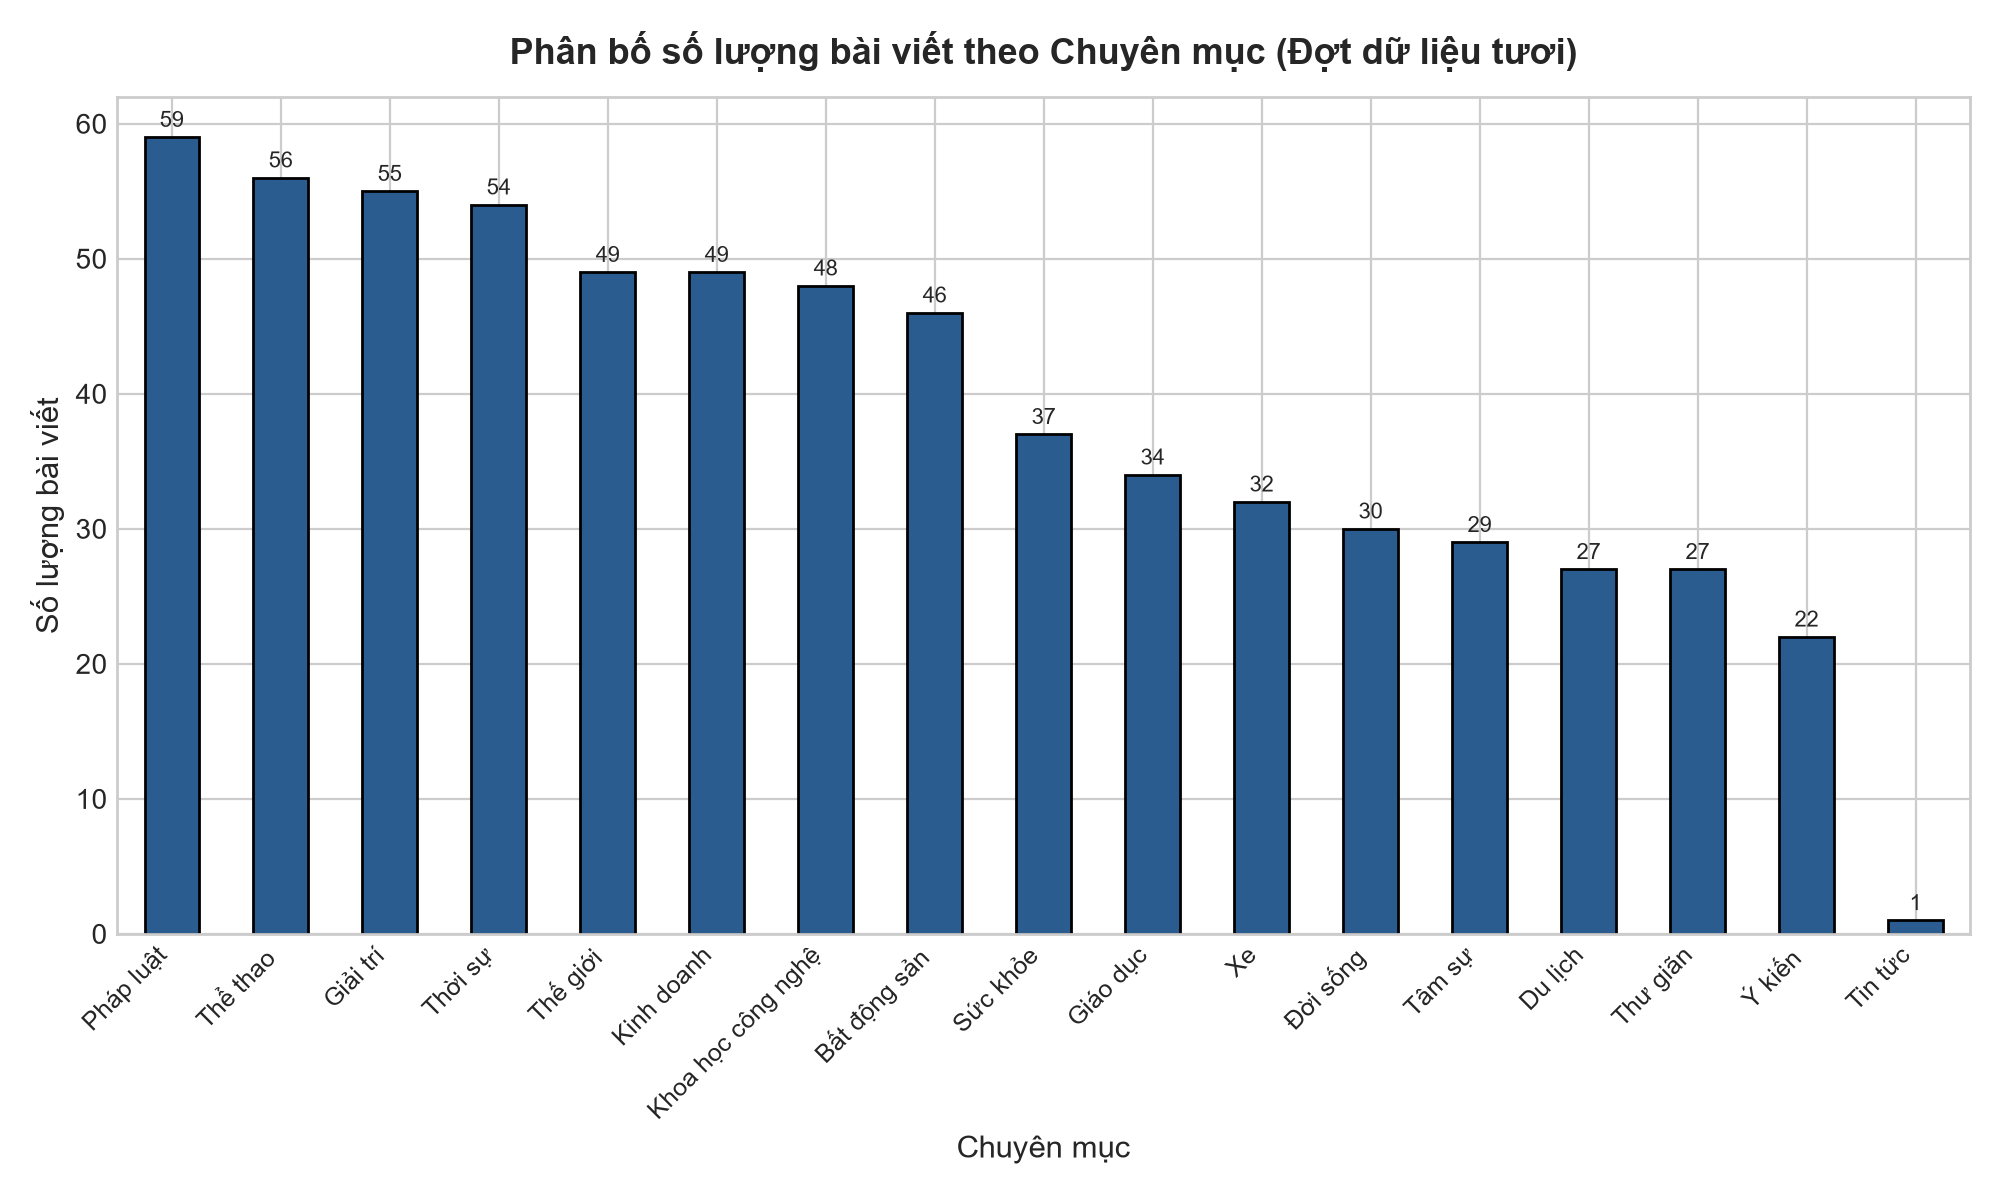


## 4.2. Biểu đồ 2: Tần số xuất bản theo Khung giờ trong ngày (0h - 23h)
**Mã nguồn Python tạo Biểu đồ 2:**


In [ ]:
# Mã nguồn tạo Biểu đồ 2: Tần số xuất bản theo Khung giờ
dt_pub = pd.to_datetime(df_clean["published_at"])
hour_counts = dt_pub.dt.hour.value_counts().sort_index()

plt.figure(figsize=(10, 4.5))
ax = hour_counts.plot(kind="line", marker="o", color="#d95f02", linewidth=2.5, markersize=6)
plt.title("Tần suất xuất bản bài viết theo Khung giờ trong ngày (0h - 23h)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Khung giờ trong ngày", fontsize=11)
plt.ylabel("Số lượng bài viết xuất bản", fontsize=11)
plt.xticks(range(0, 24))
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


**Hình ảnh xuất bản & Diễn giải nghiệp vụ:**
Xu hướng đăng bài tập trung vào **2 khung giờ vàng**: Đỉnh sáng lúc 8h - 11h và đỉnh chiều lúc 14h - 16h (phù hợp với thói quen đọc báo đầu giờ làm việc và đầu giờ chiều của độc giả).

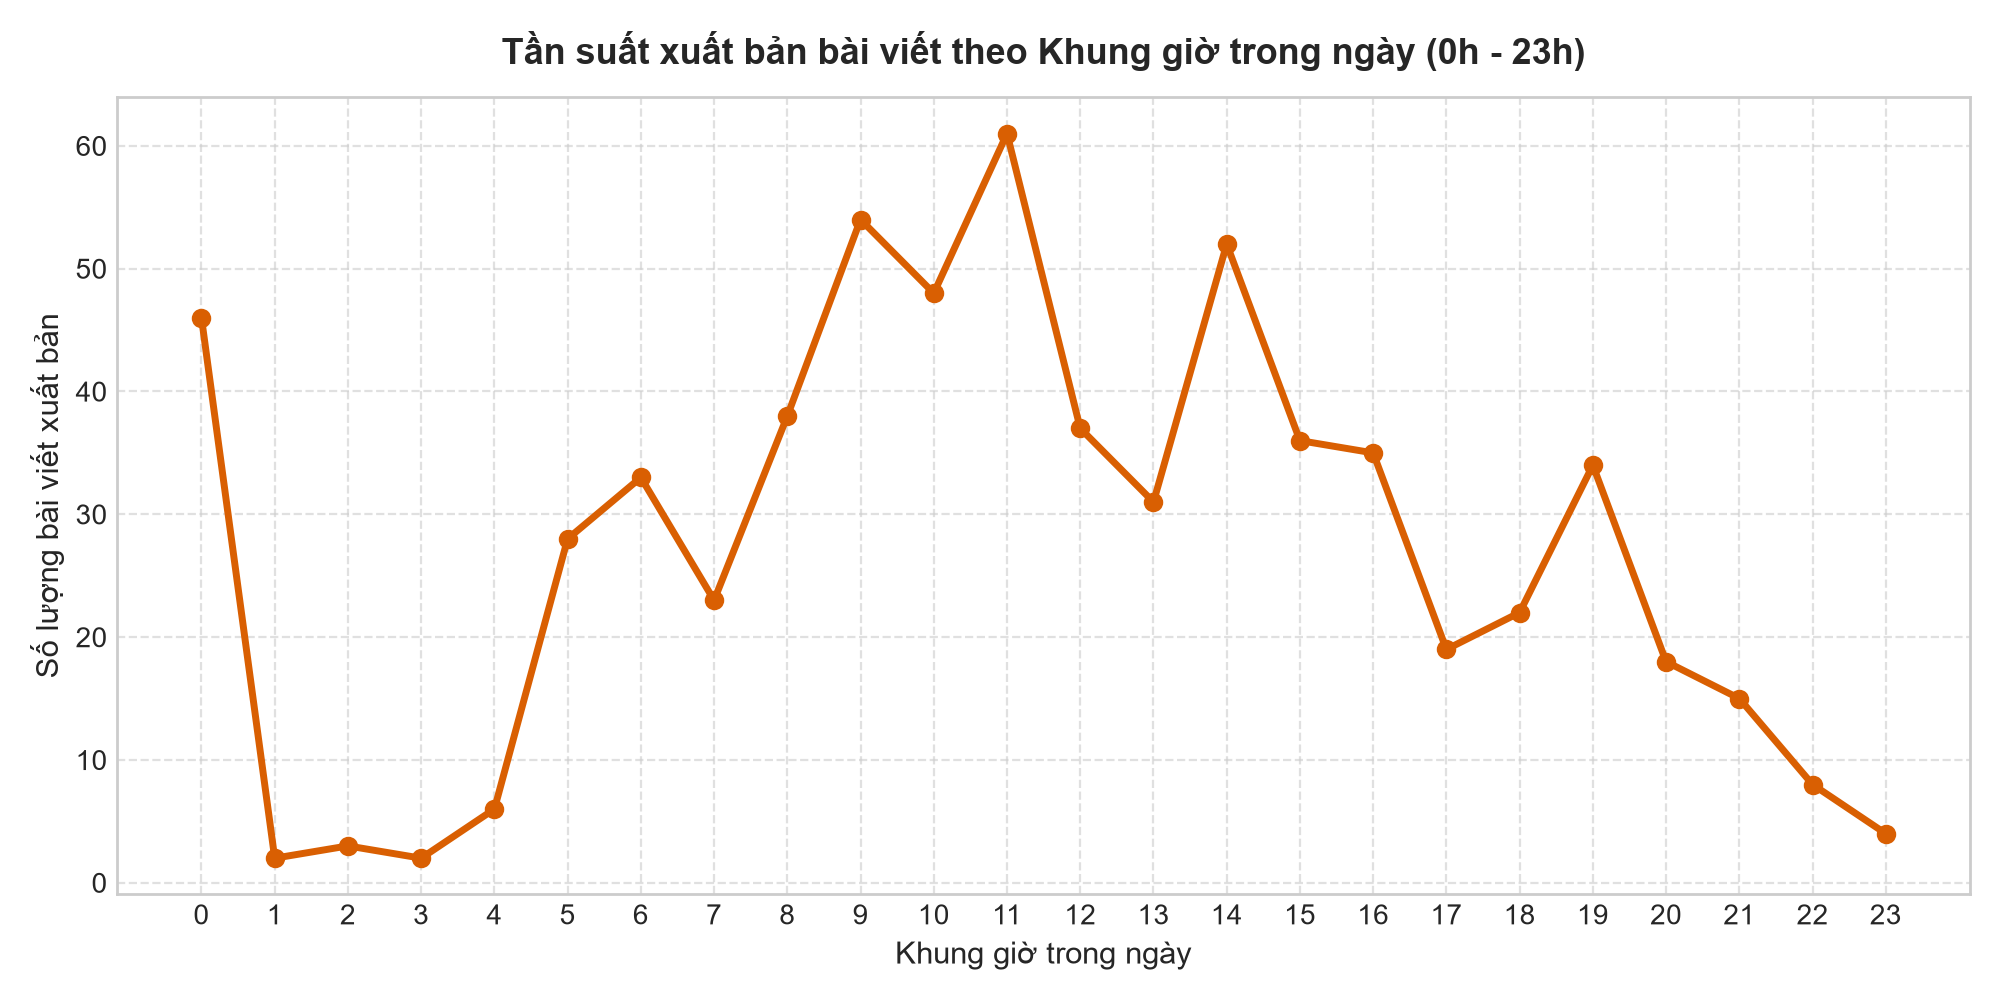


## 4.3. Biểu đồ 3: Phân bố độ dài thân bài (Word Count)
**Mã nguồn Python tạo Biểu đồ 3:**


In [ ]:
# Mã nguồn tạo Biểu đồ 3: Phân bố độ dài thân bài (Histogram / KDE)
plt.figure(figsize=(10, 4.5))
try:
    import seaborn as sns
    sns.histplot(df_clean["word_count"], kde=True, bins=35, color="#1b9e77", edgecolor="black")
except ImportError:
    plt.hist(df_clean["word_count"], bins=35, color="#1b9e77", edgecolor="black", alpha=0.7, density=True)
    df_clean["word_count"].plot(kind="kde", color="darkgreen", linewidth=2)

mean_wc = df_clean["word_count"].mean()
median_wc = df_clean["word_count"].median()
plt.axvline(mean_wc, color="red", linestyle="--", label=f"Trung bình: {mean_wc:.1f} từ")
plt.axvline(median_wc, color="blue", linestyle=":", label=f"Trung vị: {median_wc:.1f} từ")
plt.title("Phân bố độ dài bài viết (Số từ trong thân bài)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Số từ (Word count)", fontsize=11)
plt.ylabel("Số lượng bài viết", fontsize=11)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


**Hình ảnh xuất bản & Diễn giải nghiệp vụ:**
Phân bố có dạng lệch phải rõ rệt (*right-skewed*), dung lượng trung bình đạt 779.3 từ, trung vị 691.0 từ.

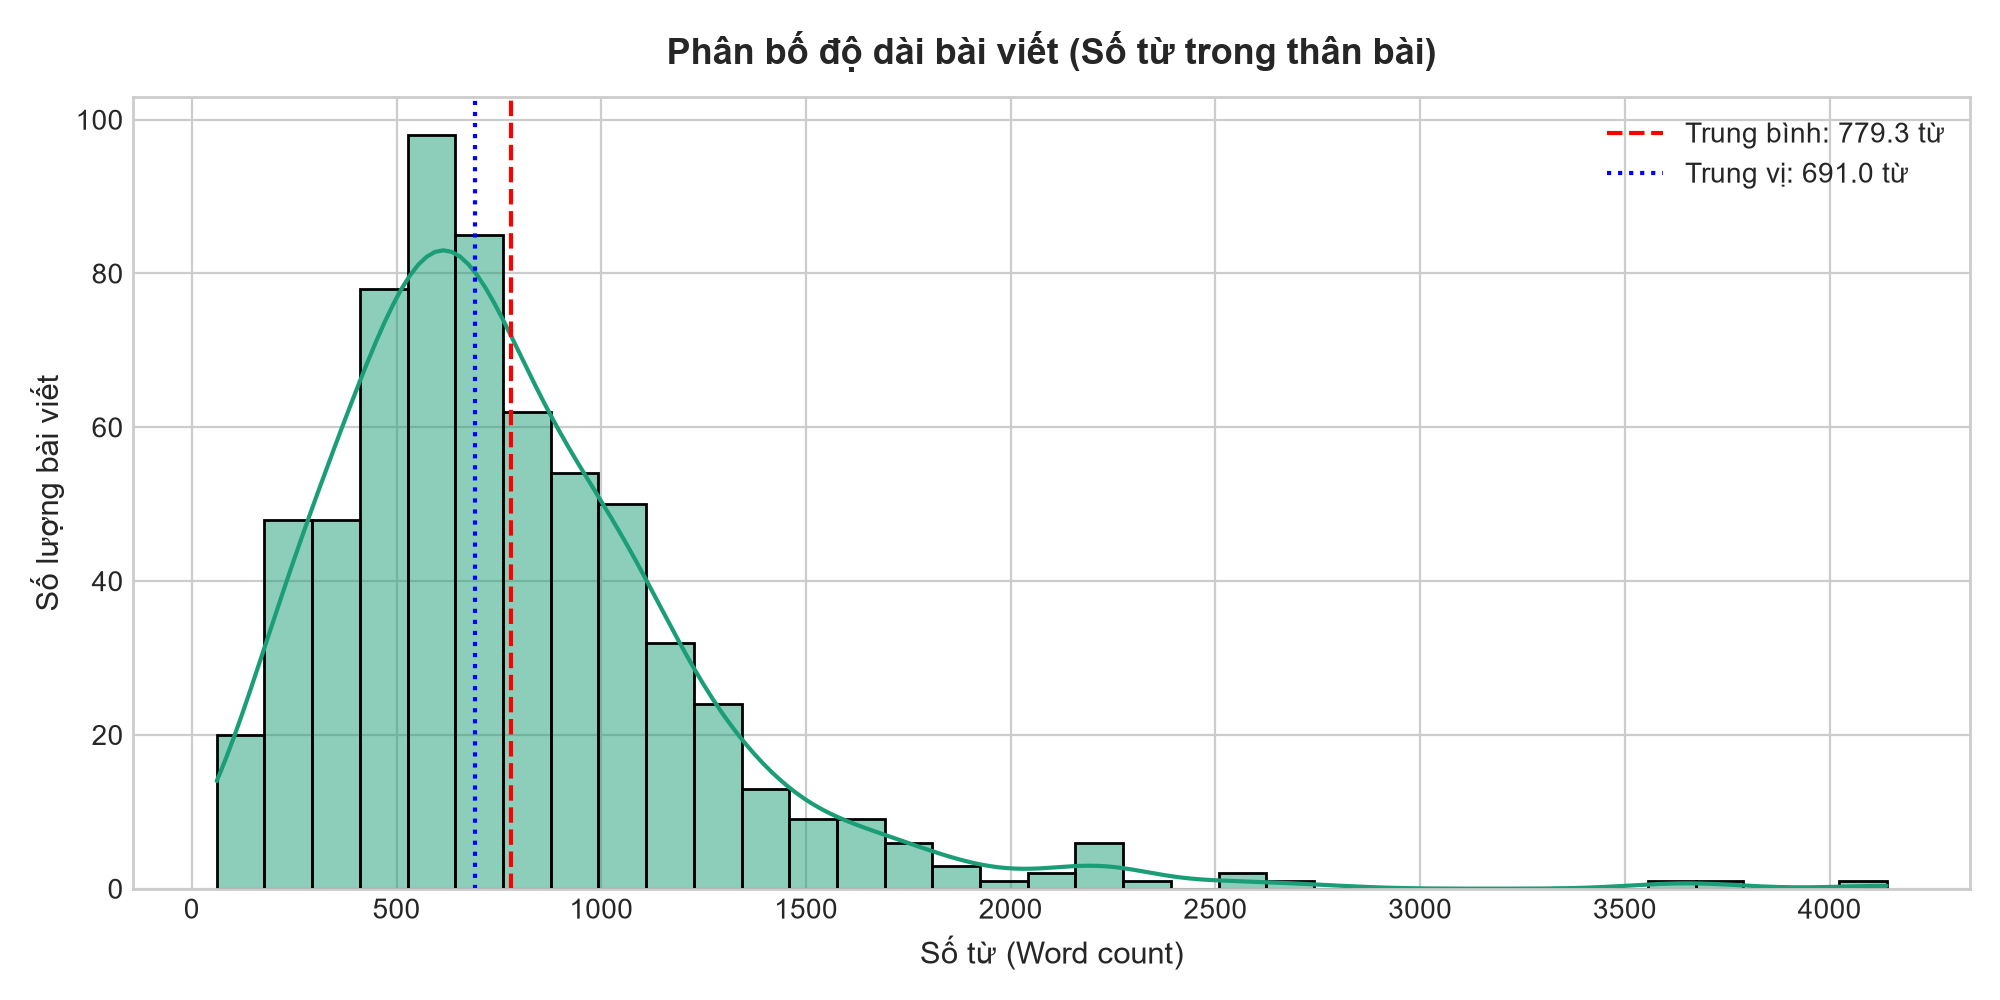


## 4.4. Biểu đồ 4: Độ dài bài viết trung bình theo Chuyên mục
**Mã nguồn Python tạo Biểu đồ 4:**


In [ ]:
# Mã nguồn tạo Biểu đồ 4: Độ dài trung bình theo Chuyên mục
plt.figure(figsize=(10, 5.5))
avg_len = df_clean.groupby("category")["word_count"].mean().sort_values(ascending=False)
ax = avg_len.plot(kind="barh", color="#7570b3", edgecolor="black")
plt.title("Độ dài bài viết trung bình theo Chuyên mục (Từ dài nhất đến ngắn nhất)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Số từ trung bình", fontsize=11)
plt.ylabel("Chuyên mục", fontsize=11)
for p in ax.patches:
    ax.annotate(f"{p.get_width():.0f}", (p.get_width(), p.get_y() + p.get_height() / 2.),
                ha="left", va="center", fontsize=8, xytext=(3, 0), textcoords="offset points")
plt.tight_layout()
plt.show()


**Hình ảnh xuất bản & Diễn giải nghiệp vụ:**
Thể thao (1,019 từ) và Bất động sản (1,003 từ) là những chuyên mục có dung lượng trung bình dài nhất do đặc thù bài chuyên đề, tường thuật chi tiết.

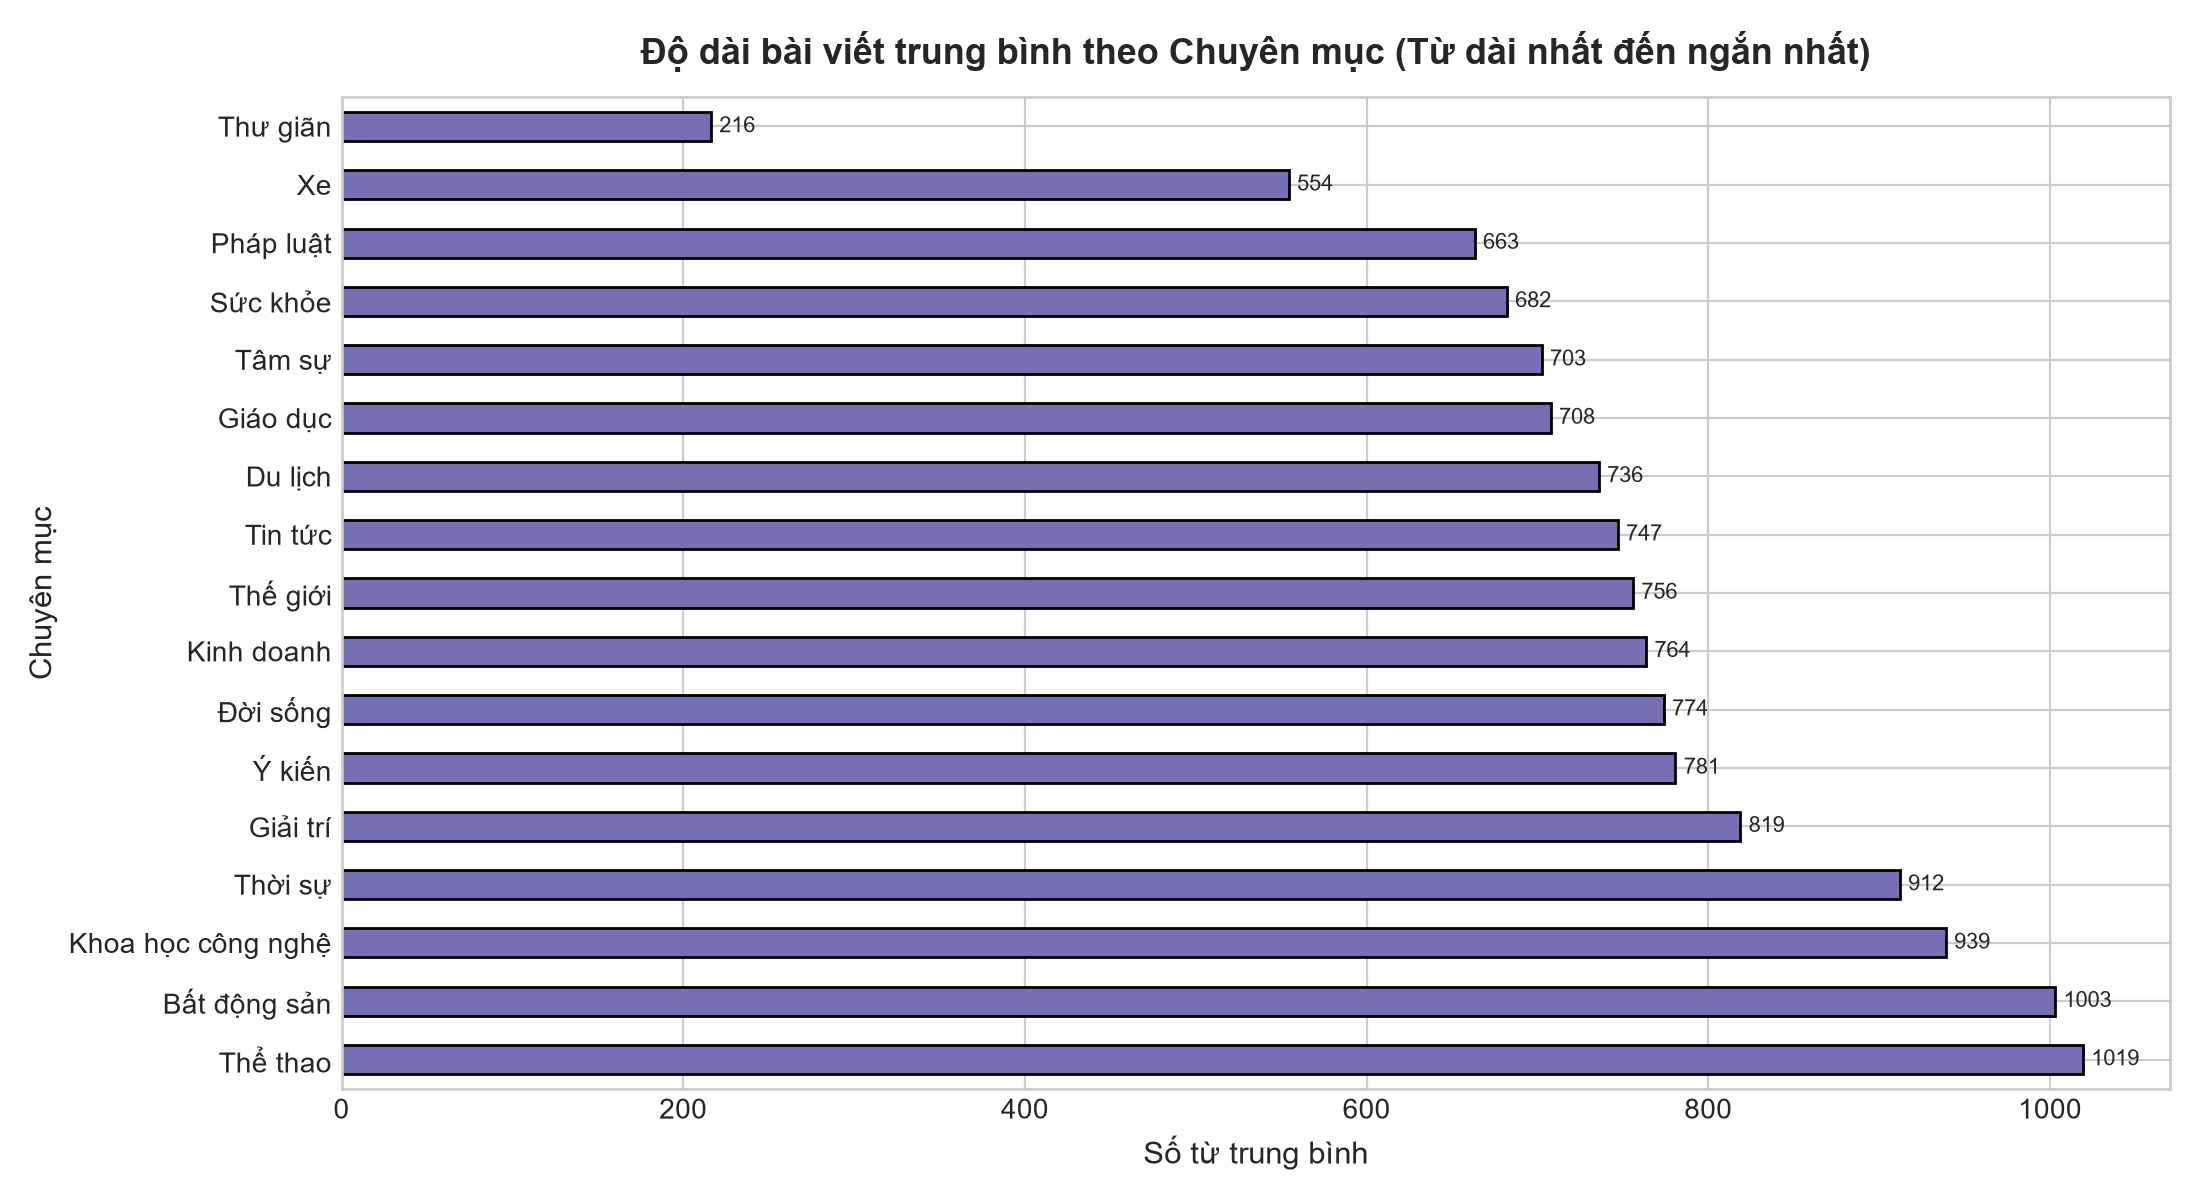


## 4.5. Biểu đồ 5: Top 10 Phóng viên / Tác giả tích cực nhất
**Mã nguồn Python tạo Biểu đồ 5:**


In [ ]:
# Mã nguồn tạo Biểu đồ 5: Top 10 Phóng viên có nhiều bài viết nhất
plt.figure(figsize=(10, 4.5))
top_authors = df_clean[df_clean["author"] != "VnExpress"]["author"].value_counts().head(10)
ax = top_authors.plot(kind="bar", color="#e7298a", edgecolor="black")
plt.title("Top 10 Tác giả / Phóng viên có nhiều bài viết nhất (Ngoại trừ tòa soạn)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Tác giả / Bút danh phóng viên", fontsize=11)
plt.ylabel("Số lượng bài viết", fontsize=11)
plt.xticks(rotation=35, ha="right", fontsize=9)
for p in ax.patches:
    ax.annotate(str(int(p.get_height())), (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="bottom", fontsize=8, xytext=(0, 2), textcoords="offset points")
plt.tight_layout()
plt.show()


**Hình ảnh xuất bản & Diễn giải nghiệp vụ:**
Nhận diện thành công 226 danh tính tác giả/bút danh độc nhất, trong đó các phóng viên Mộc Trà, Hồng Duy, Hà Thu có năng suất xuất bản cao nhất trong tuần.

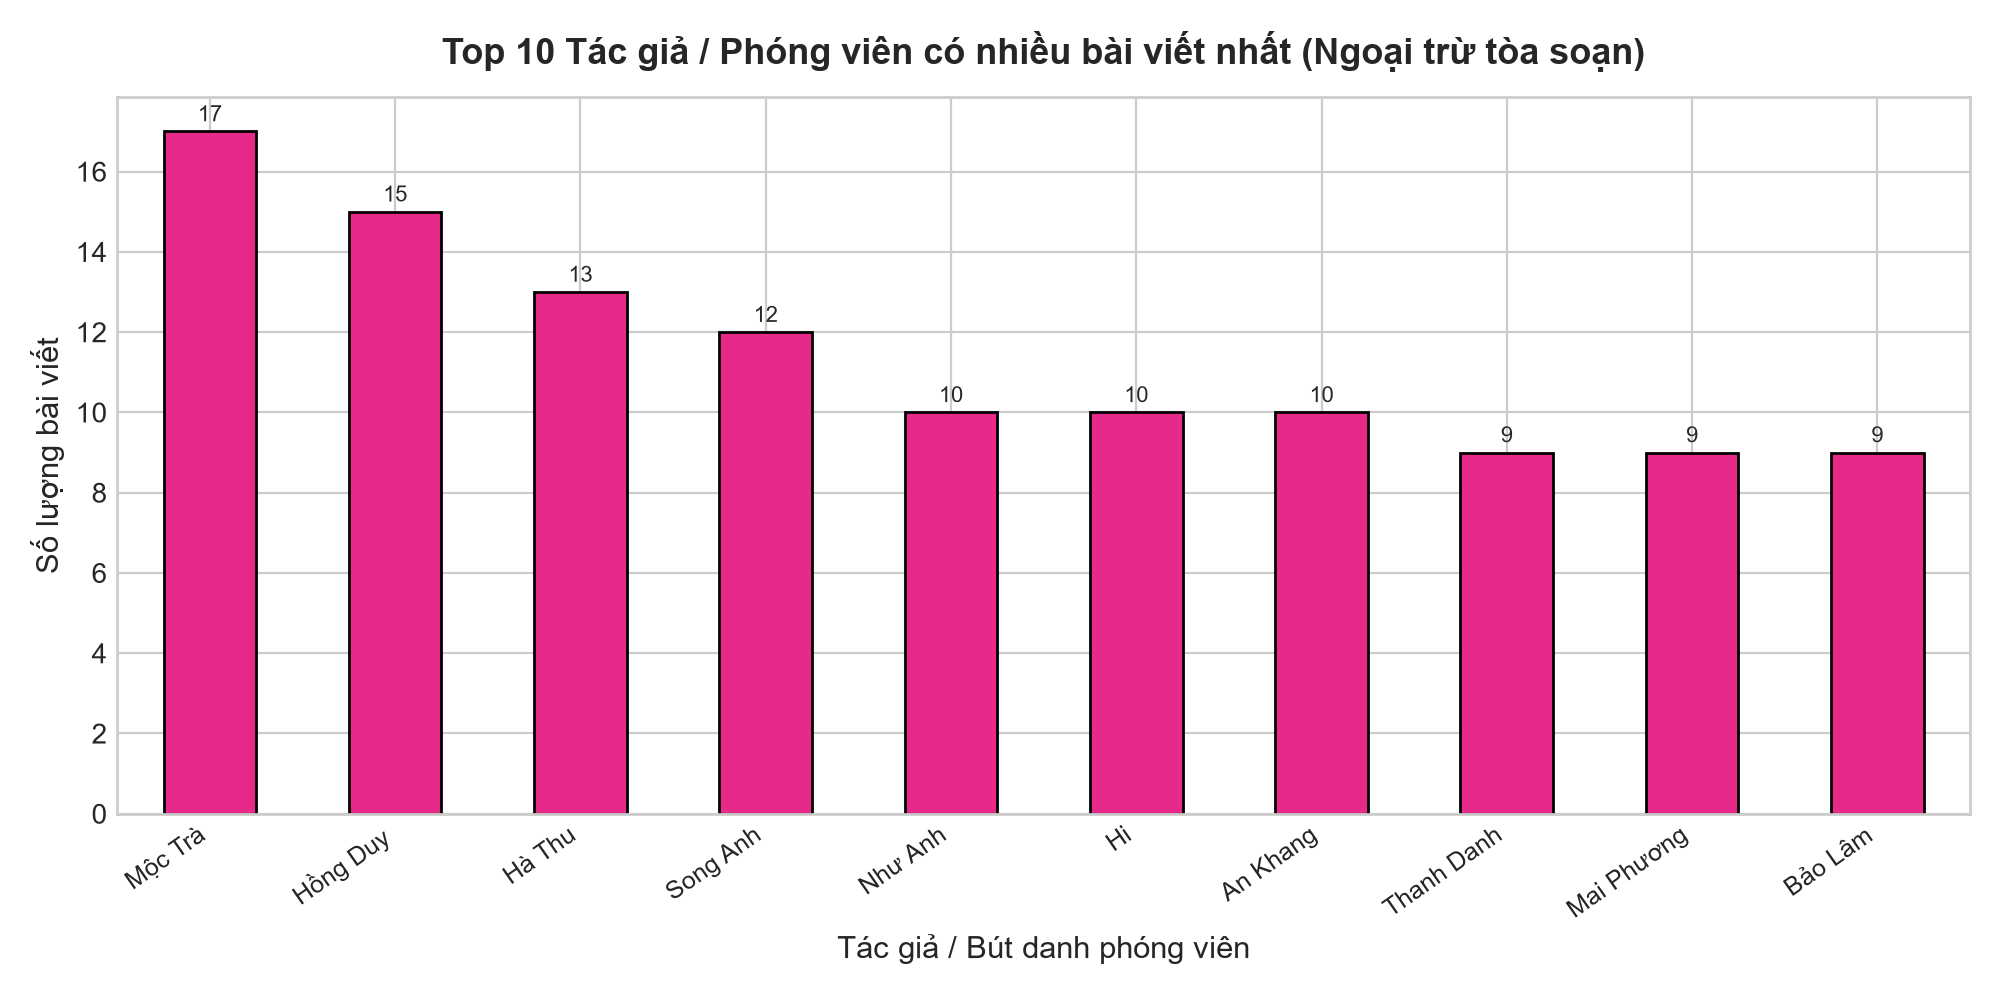


---
# CHƯƠNG 5: HUẤN LUYỆN VÀ ĐÁNH GIÁ MÔ HÌNH HỌC MÁY (PHASE 5 & PHASE 6)
### *Thành viên phụ trách: Đinh Trung Hiếu*

## 5.1. Phân loại Thể loại Báo chí (Text Classification)
- **Đặc trưng:** TF-IDF (4,000 từ khóa, n-gram 1-2) trích xuất từ `title + description + content`.
- **Phân chia:** Stratified Split 80% Train (523 bài) / 20% Test (131 bài) trên 16 lớp chuyên mục.
- **Mô hình thử nghiệm:** Linear SVM, Multinomial Naive Bayes, Logistic Regression, Decision Tree.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Lọc bỏ các chuyên mục dưới 10 bài để đảm bảo phân tầng
cat_counts = df_clean["category"].value_counts()
valid_cats = cat_counts[cat_counts >= 10].index
df_clf = df_clean[df_clean["category"].isin(valid_cats)].copy()

df_clf["text_features"] = df_clf["title"] + " " + df_clf["description"] + " " + df_clf["content"]
X_clf = df_clf["text_features"]
y_clf = df_clf["category"]

X_train, X_test, y_train, y_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

vectorizer = TfidfVectorizer(max_features=4000, ngram_range=(1, 2), min_df=2)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

clf_models = {
    "Linear SVM": LinearSVC(C=1.0, random_state=42, dual="auto"),
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.1),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=30, random_state=42)
}

eval_summary = {}
for name, model in clf_models.items():
    model.fit(X_train_vec, y_train)
    y_pred = model.predict(X_test_vec)
    eval_summary[name] = {
        "Accuracy": f"{accuracy_score(y_test, y_pred)*100:.2f}%",
        "Precision (Weighted)": f"{precision_score(y_test, y_pred, average='weighted', zero_division=0)*100:.2f}%",
        "Recall (Weighted)": f"{recall_score(y_test, y_pred, average='weighted', zero_division=0)*100:.2f}%",
        "Weighted F1": f"{f1_score(y_test, y_pred, average='weighted', zero_division=0)*100:.2f}%"
    }

print("[+] BẢNG SO SÁNH HIỆU NĂNG 4 THUẬT TOÁN PHÂN LOẠI VĂN BẢN:")
display(pd.DataFrame(eval_summary).T)


### 5.2. Trực quan hóa Ma trận Nhầm lẫn & So sánh Thuật toán
- **Linear SVM** đạt kết quả cao nhất (**83.21% Accuracy**, **81.66% Weighted F1**) nhờ khả năng tối ưu hóa khoảng cách lề (margin) vượt trội trên không gian đặc trưng thưa số chiều cao.

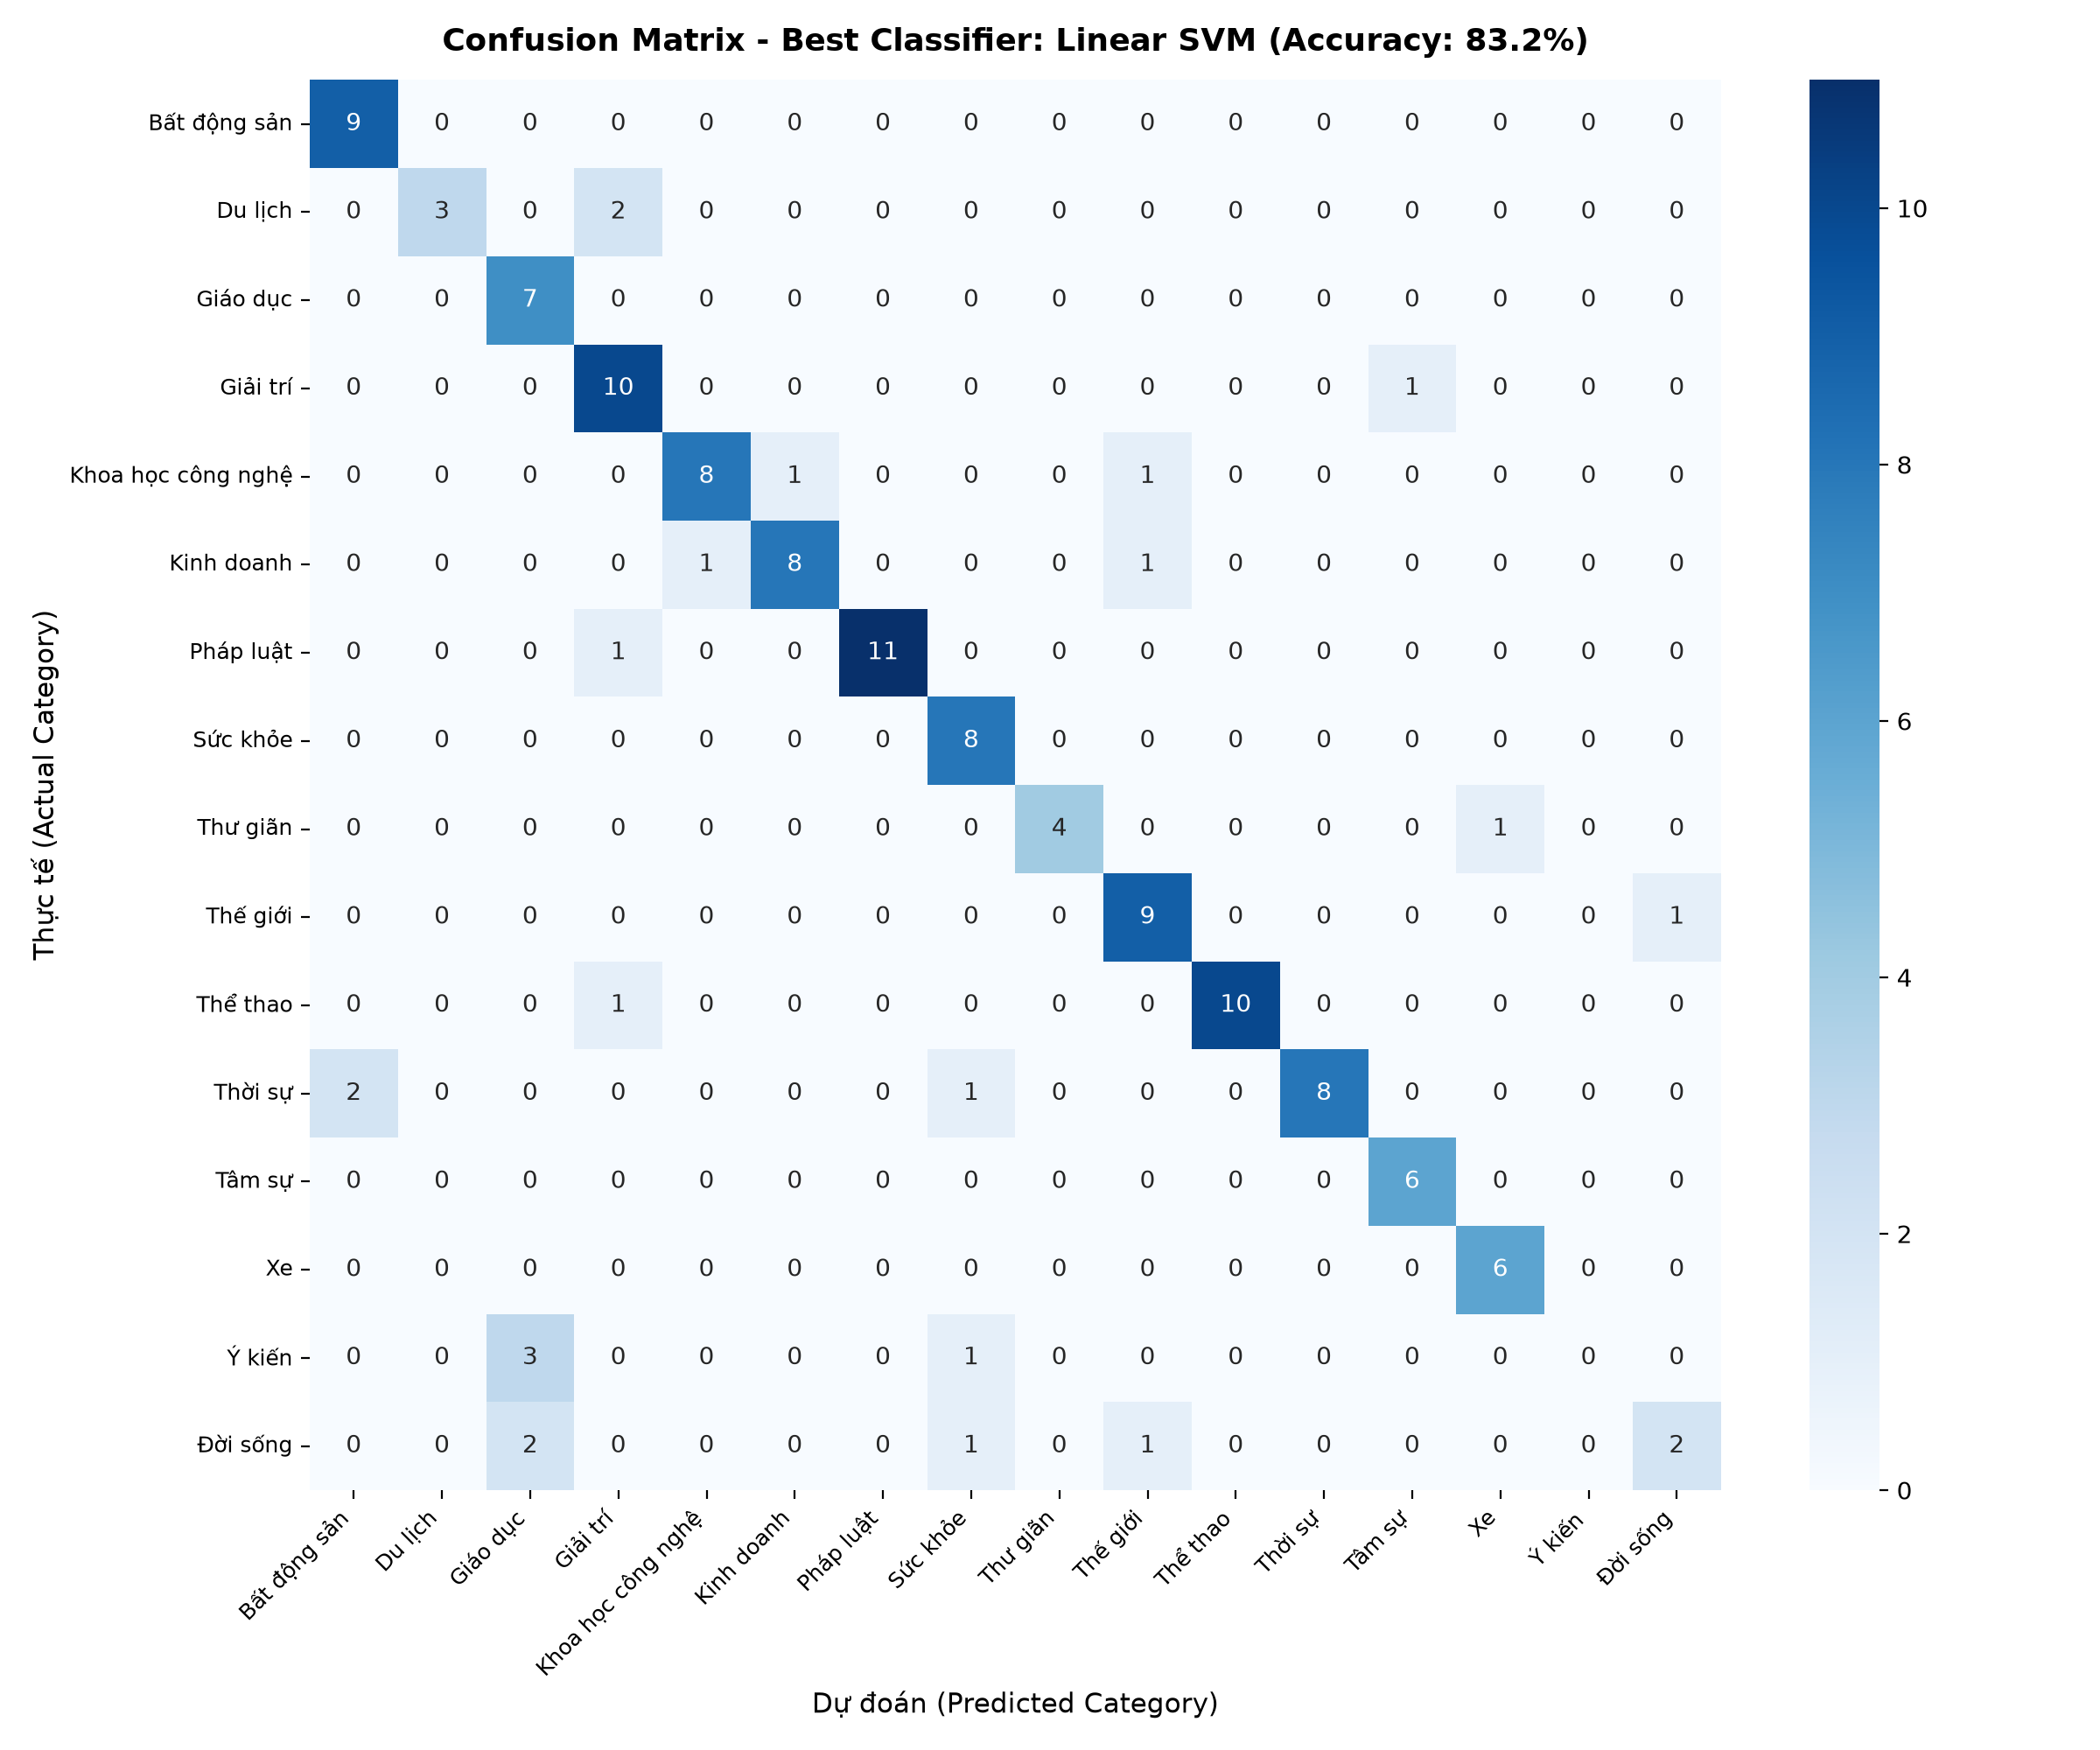

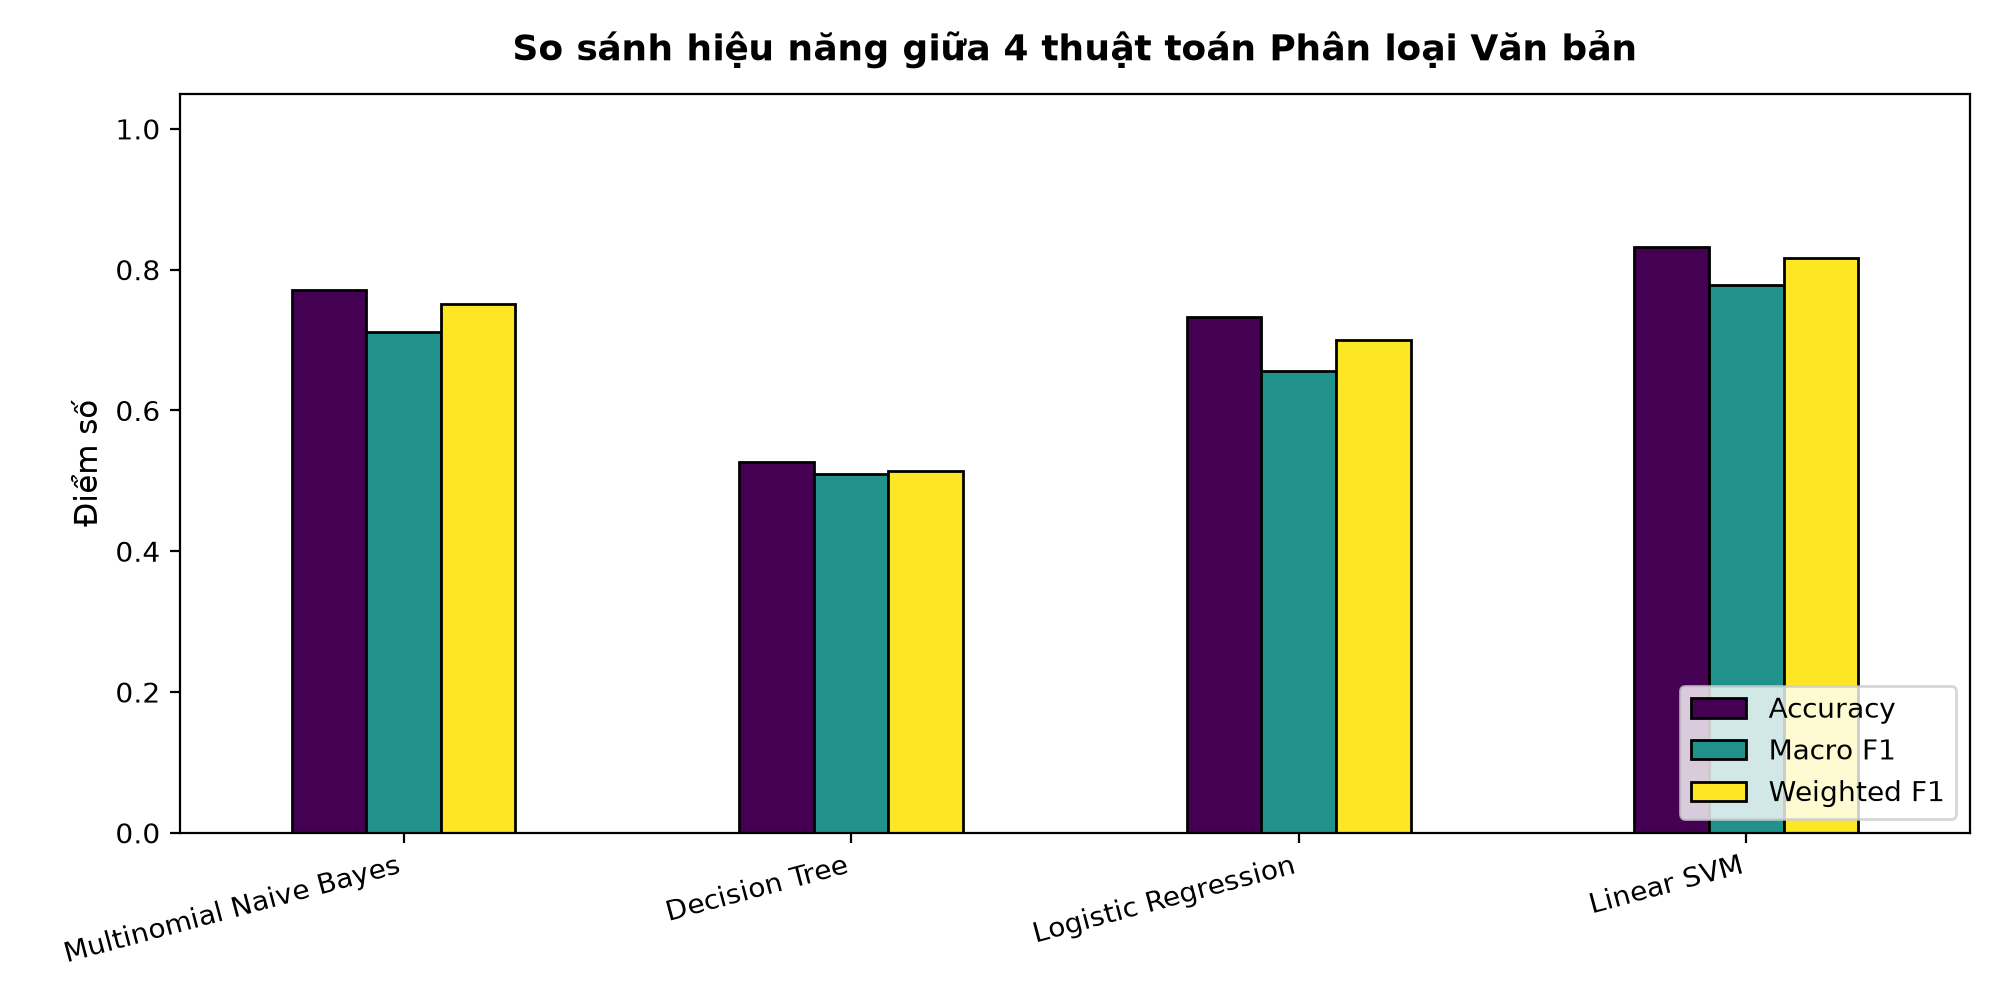


## 5.3. Mô hình Hồi quy Dự đoán Dung lượng Bài viết (Regression Modeling)
- **Biến mục tiêu ($y$):** `word_count` (Số từ của thân bài).
- **Biến giải thích ($X$):** Siêu dữ liệu xuất bản (Metadata: số từ tiêu đề, số từ sapo, giờ đăng, thứ, cuối tuần, One-Hot Encoding chuyên mục).
- **Cam kết học thuật:** **No Data Leakage** — Tuyệt đối không dùng thông tin thân bài để đoán thân bài.


In [ ]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

df_reg = df_clean.copy()
df_reg["title_words"] = df_reg["title"].fillna("").apply(lambda t: len(str(t).split()))
df_reg["desc_words"] = df_reg["description"].fillna("").apply(lambda d: len(str(d).split()))
dt_pub = pd.to_datetime(df_reg["published_at"])
df_reg["publish_hour"] = dt_pub.dt.hour
df_reg["publish_dayofweek"] = dt_pub.dt.dayofweek
df_reg["is_weekend"] = dt_pub.dt.dayofweek.apply(lambda d: 1 if d >= 5 else 0)

cat_dummies = pd.get_dummies(df_reg["category"], prefix="cat", drop_first=True, dtype=int)
features = ["title_words", "desc_words", "publish_hour", "publish_dayofweek", "is_weekend"]
X_reg = pd.concat([df_reg[features], cat_dummies], axis=1)
y_reg = df_reg["word_count"]

X_tr, X_te, y_tr, y_te = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

reg_models = {
    "Ridge Regression": Ridge(alpha=1.0),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
}

reg_eval = {}
for r_name, r_mod in reg_models.items():
    r_mod.fit(X_tr, y_tr)
    y_pred_r = r_mod.predict(X_te)
    reg_eval[r_name] = {
        "MAE (Từ)": round(mean_absolute_error(y_te, y_pred_r), 2),
        "RMSE (Từ)": round(root_mean_squared_error(y_te, y_pred_r), 2),
        "R² Score": round(r2_score(y_te, y_pred_r), 4)
    }

print("[+] BẢNG ĐO LƯỜNG SAI SỐ MÔ HÌNH HỒI QUY:")
display(pd.DataFrame(reg_eval).T)


### 5.4. Đồ thị Thực tế vs Dự đoán & Đồ thị Phần dư
Hệ số $R^2 pprox 0.16$ phản ánh tính trung thực và khách quan của khoa học dữ liệu: Dung lượng một bài báo thực tế phụ thuộc vào tính thời sự của sự việc và ngòi bút của phóng viên, siêu dữ liệu chỉ giải thích một phần biến thiên này.

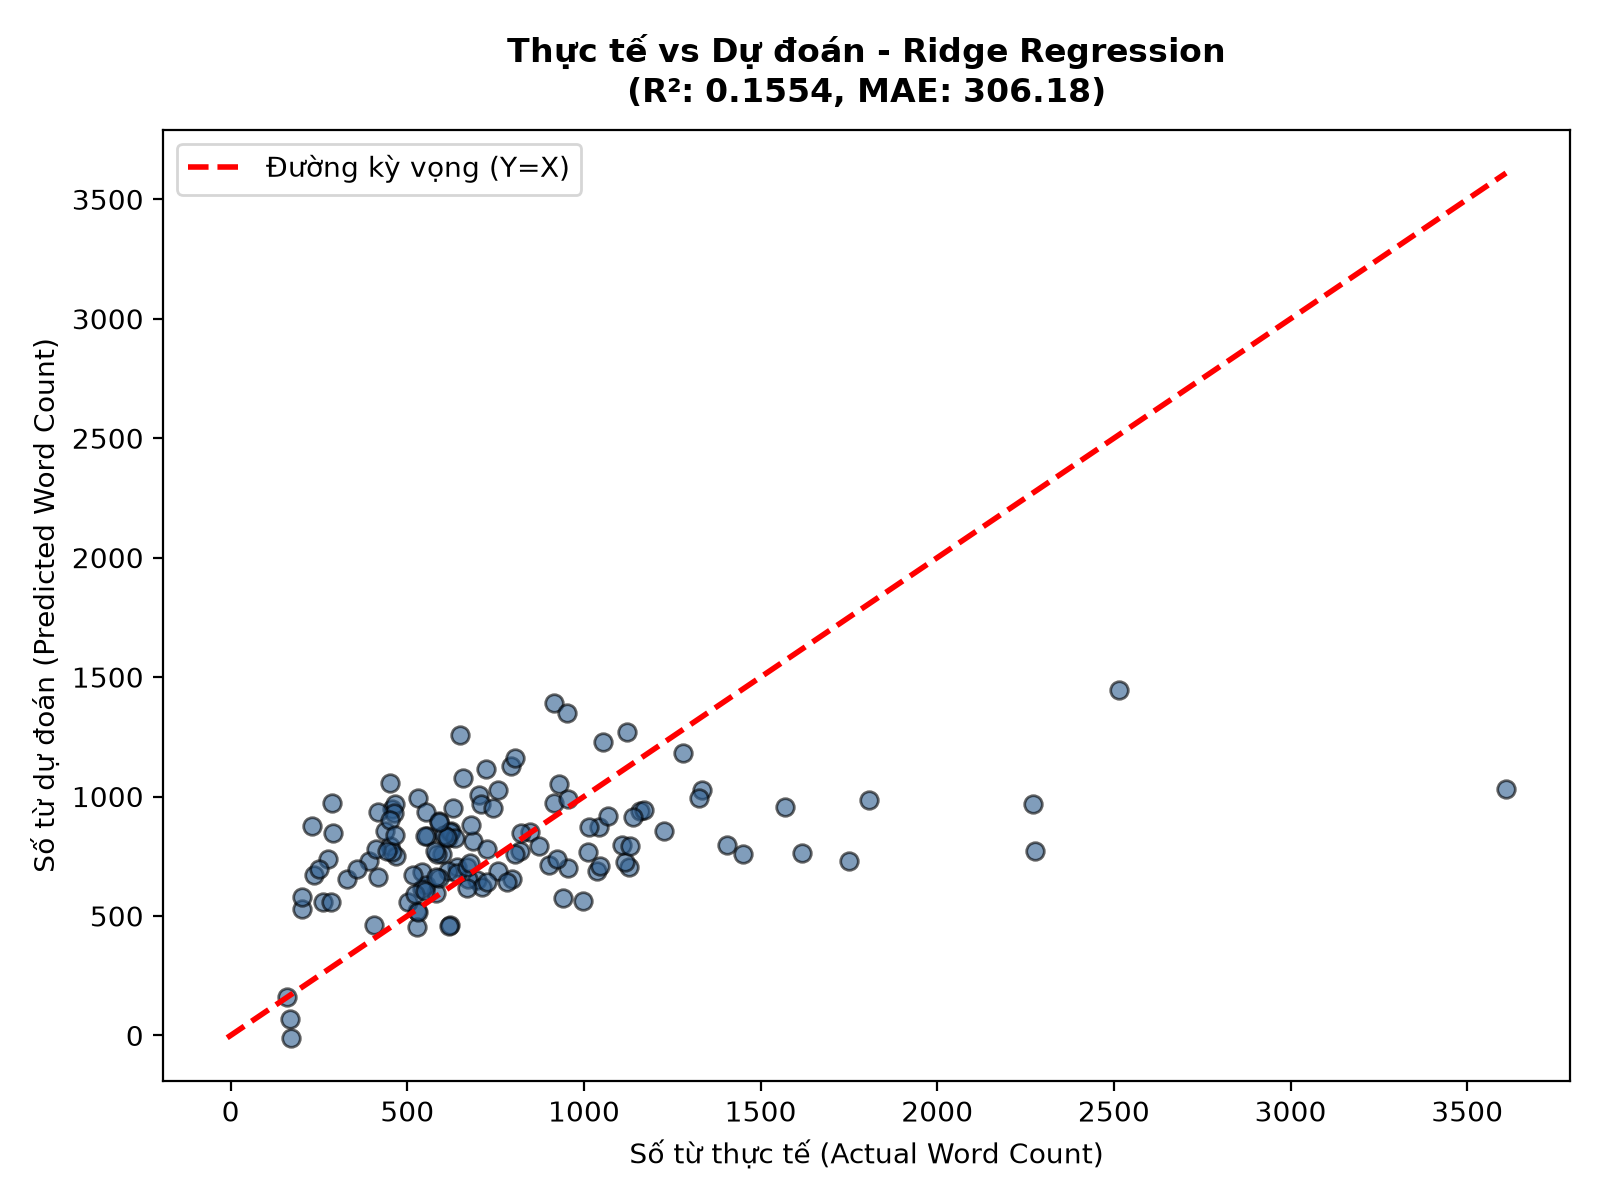

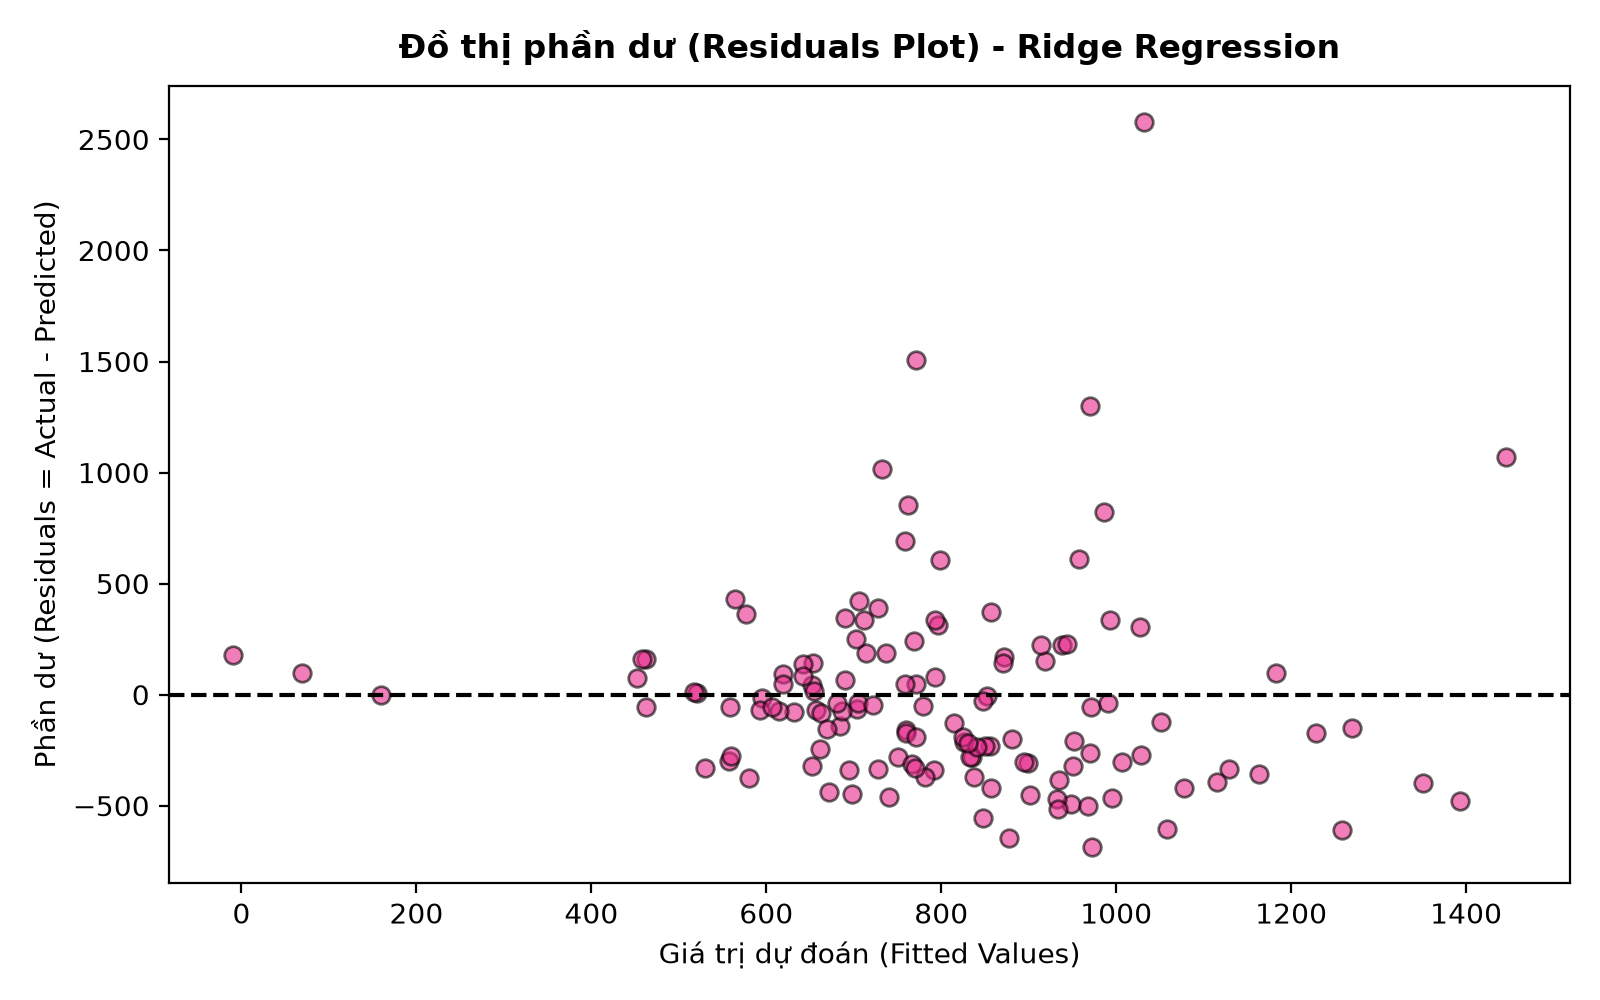

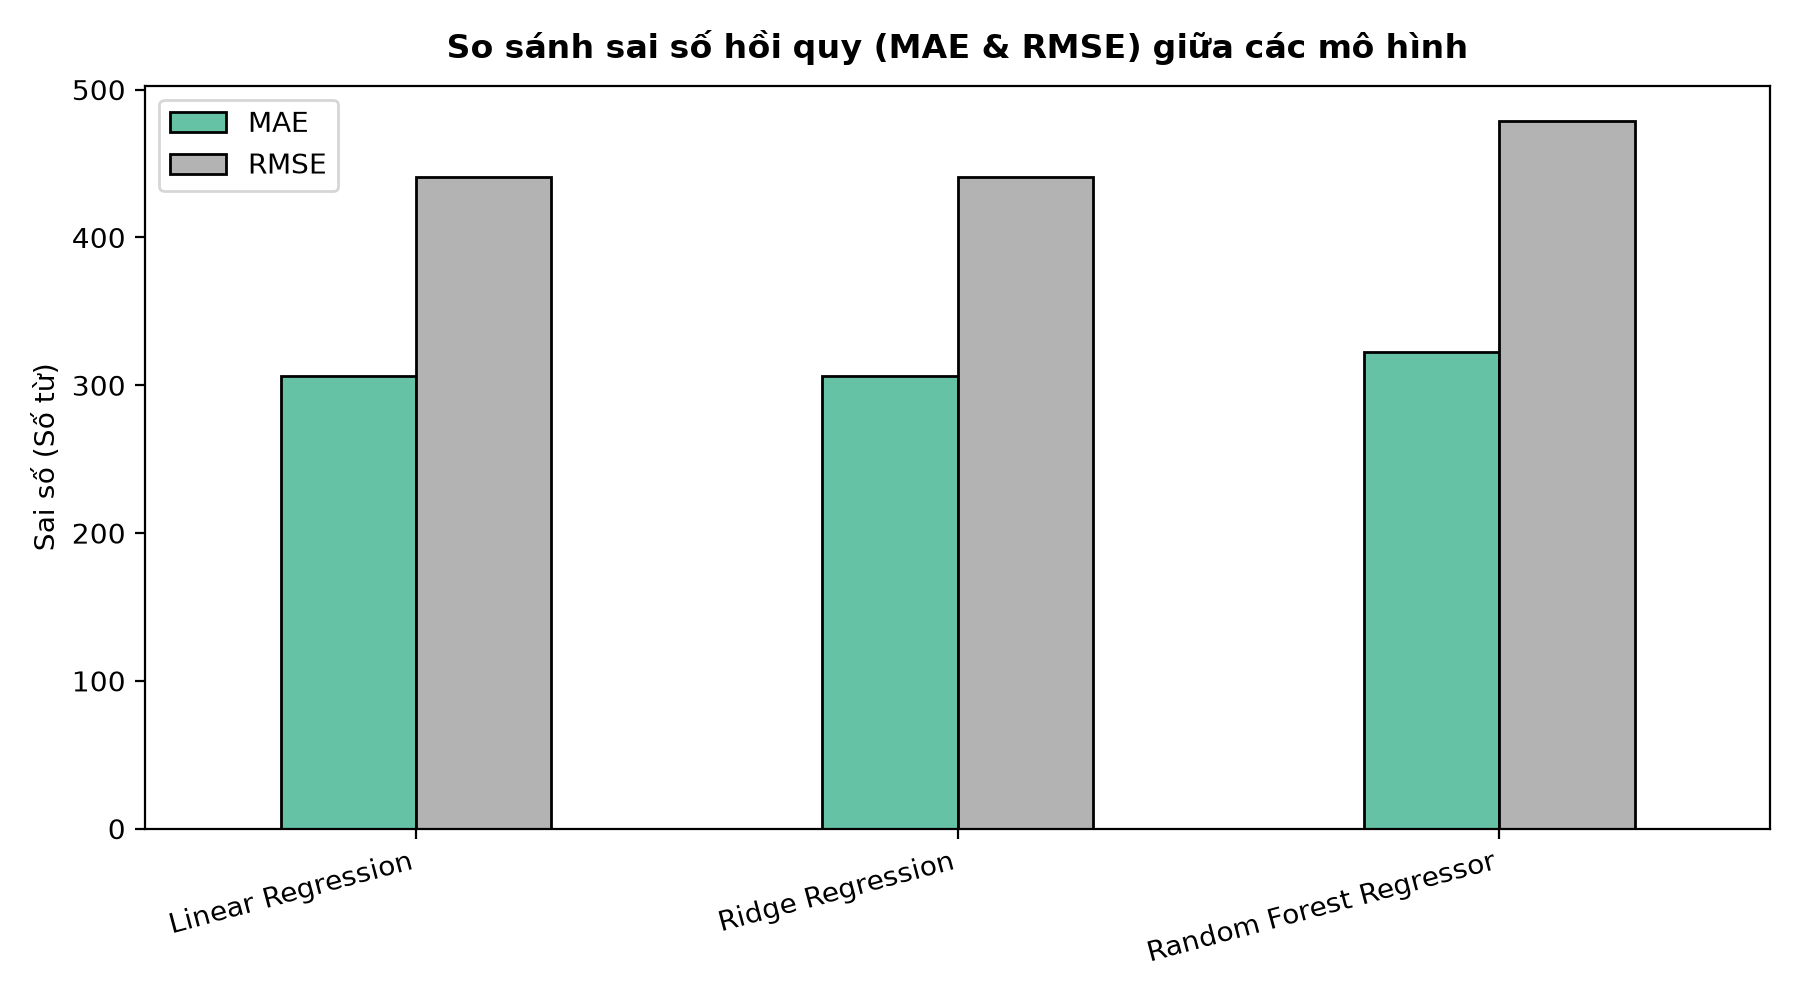


### 5.5. Ứng dụng Triển khai Mô hình Dự đoán Thể loại (Deployment)
Hàm thử nghiệm dự đoán chuyên mục cho một bài báo mới:


In [ ]:
# Hàm dự đoán bài viết mới
best_classifier = clf_models["Linear SVM"]

def predict_article_category(title, description, content):
    sample_text = f"{title} {description} {content}"
    sample_vec = vectorizer.transform([sample_text])
    predicted_category = best_classifier.predict(sample_vec)[0]
    return predicted_category

# Test thử nghiệm bài báo thực tế
sample_title = "Tuyển Việt Nam thắng đậm trận ra quân giải vô địch Đông Nam Á"
sample_desc = "Các học trò thi đấu hưng phấn và ghi 3 bàn thắng đẹp mắt trước đối thủ."
sample_content = "Đội tuyển đã có thế trận áp đảo, liên tục kiểm soát bóng và giành trọn vẹn 3 điểm trong ngày thi đấu xuất sắc của hàng tiền đạo."

res_cat = predict_article_category(sample_title, sample_desc, sample_content)
print(f"Tiêu đề: {sample_title}")
print(f"👉 Thể loại dự đoán: [{res_cat}]")
